# Fashion-MNIST Classification — Professional Machine Learning & ANN Workflow

**A reproducible, end-to-end notebook** combining exploratory data analysis, scikit-learn baselines, a PyTorch artificial neural network, model diagnostics, and interactive Plotly reporting.

| Project detail | Specification |
|---|---|
| Dataset | Fashion-MNIST CSV files supplied with this project |
| Training data | 60,000 labelled grayscale images |
| Test data | 10,000 labelled grayscale images |
| Image dimensions | 28 × 28 pixels (784 features) |
| Target | 10 fashion categories |
| Models | Dummy baseline, scikit-learn SGD classifier, PyTorch ANN |
| Visuals | Matplotlib PNGs and interactive Plotly HTML files |
| Output folders | `images/` and `artifacts/` |

> **Run from top to bottom.** Put `fashion-mnist_train.csv` and `fashion-mnist_test.csv` in the same folder as this notebook, or update the paths in the configuration section. The notebook creates the output folders automatically.

**Reproducibility note:** the provided test CSV is held out for final evaluation. The training CSV is split into training and validation subsets; the test set is not used for fitting or model selection.

## Notebook roadmap

1. Environment, reproducibility, and project folders
2. Dataset loading, schema validation, and data-quality checks
3. Exploratory analysis with saved Matplotlib and Plotly figures
4. Train/validation preparation and PCA exploration
5. scikit-learn baselines and diagnostic metrics
6. PyTorch ANN architecture, training, and validation
7. Final evaluation, error analysis, and single-image inference
8. Export models, predictions, tables, metrics, and run metadata

The notebook contains **exactly 100 executable code cells**. Markdown cells are used for section titles and explanations.

## 1. Environment and imports

The project uses NumPy and pandas for data handling, Matplotlib and Plotly for visual analysis, scikit-learn for classical machine learning and metrics, and PyTorch for the ANN. Install missing packages only when needed.

In [1]:
# Optional dependency installation (run in a terminal if a package is missing):
# python -m pip install numpy pandas matplotlib scikit-learn plotly torch joblib ipython

In [2]:
# Core Python utilities
import os
import sys
import json
import time
import copy
import random
import platform
import warnings
from pathlib import Path

# Data handling
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import plotly.express as px
import plotly.graph_objects as go

# scikit-learn: splitting, dimensionality reduction, baseline models, and metrics
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score,
)
from sklearn.calibration import calibration_curve
from joblib import dump

# PyTorch ANN
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
print("All core libraries imported successfully.")

All core libraries imported successfully.


In [3]:
# Capture library versions for reproducibility and troubleshooting.
versions = {
    "Python": platform.python_version(),
    "NumPy": np.__version__,
    "pandas": pd.__version__,
    "Matplotlib": plt.matplotlib.__version__,
    "Plotly": px.__version__ if hasattr(px, "__version__") else __import__("plotly").__version__,
    "scikit-learn": __import__("sklearn").__version__,
    "PyTorch": torch.__version__,
}
version_table = pd.DataFrame({"Library": versions.keys(), "Version": versions.values()})
display(version_table)

,Library,Version
0,Python,3.14.7
1,NumPy,2.5.4
2,pandas,3.1.0
3,Matplotlib,3.11.2
4,Plotly,7.1.0
5,scikit-learn,1.9.1
6,PyTorch,2.14.1+cu132


In [4]:
# Fix random seeds across Python, NumPy, and PyTorch.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
# Prevent CPU thread oversubscription on hosted notebooks and typical laptops.
torch.set_num_threads(min(4, os.cpu_count() or 1))
try:
    torch.set_num_interop_threads(1)
except RuntimeError:
    pass
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Use deterministic algorithms where practical without forcing slow kernels.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Random seed: {SEED}")
print(f"Compute device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Random seed: 42
Compute device: cpu


In [5]:
# Central configuration: make experiment changes here rather than across the notebook.
TRAIN_CSV_NAME = "fashion-mnist_train.csv"
TEST_CSV_NAME = "fashion-mnist_test.csv"
VALIDATION_SIZE = 0.10
BATCH_SIZE = 256
EVAL_BATCH_SIZE = 512
MAX_EPOCHS = 12
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
DROPOUT_RATE = 0.30
EARLY_STOPPING_PATIENCE = 4
SGD_MAX_ITER = 20
PCA_COMPONENTS = 50
MAX_PCA_SAMPLES = 12_000
NUM_WORKERS = 0  # robust default for Windows and notebook environments

print("Experiment configuration loaded.")

Experiment configuration loaded.


In [6]:
# Create the requested output structure beside the notebook's working directory.
PROJECT_ROOT = Path.cwd()
IMAGES_DIR = PROJECT_ROOT / "images"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
IMAGES_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root :", PROJECT_ROOT.resolve())
print("Images       :", IMAGES_DIR.resolve())
print("Artifacts    :", ARTIFACTS_DIR.resolve())

Project root : C:\Users\as178\OneDrive\Documents\ROADMAP\Semester 3\Deep Learning\Pytorch
Images       : C:\Users\as178\OneDrive\Documents\ROADMAP\Semester 3\Deep Learning\Pytorch\images
Artifacts    : C:\Users\as178\OneDrive\Documents\ROADMAP\Semester 3\Deep Learning\Pytorch\artifacts


In [7]:
# Shared export helpers keep every graph and generated data file in the correct folder.
def save_matplotlib(fig, filename, dpi=180):
    path = IMAGES_DIR / filename
    fig.savefig(path, dpi=dpi, bbox_inches="tight", facecolor="white")
    return path


def save_plotly(fig, filename):
    path = IMAGES_DIR / filename
    fig.write_html(path, include_plotlyjs="cdn", full_html=True)
    return path


def save_csv(frame, filename, index=False):
    path = ARTIFACTS_DIR / filename
    frame.to_csv(path, index=index)
    return path


def save_json(payload, filename):
    path = ARTIFACTS_DIR / filename
    with path.open("w", encoding="utf-8") as file:
        json.dump(payload, file, indent=4, default=lambda value: value.item() if isinstance(value, np.generic) else str(value))
    return path

print("Export helpers are ready.")

Export helpers are ready.


## 2. Load and validate the Fashion-MNIST data

Each CSV is expected to contain one target column (`label`) followed by 784 pixel columns. Pixel values should be integers from 0 through 255.

In [8]:
def find_dataset_file(filename):
    """Search common notebook, Colab, Kaggle, and mounted-upload locations."""
    candidates = [
        Path.cwd() / filename,
        Path.cwd() / "data" / filename,
        Path("/mnt/data") / filename,
        Path("/content") / filename,
        Path("/content/data") / filename,
        Path("/kaggle/input") / filename,
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate.resolve()
    return None

TRAIN_CSV_PATH = find_dataset_file(TRAIN_CSV_NAME)
TEST_CSV_PATH = find_dataset_file(TEST_CSV_NAME)
print("Training CSV:", TRAIN_CSV_PATH)
print("Test CSV    :", TEST_CSV_PATH)
if TRAIN_CSV_PATH is None or TEST_CSV_PATH is None:
    raise FileNotFoundError(
        "Both Fashion-MNIST CSV files are required. Put them beside the notebook "
        "or update TRAIN_CSV_PATH and TEST_CSV_PATH manually."
    )

# Anchor exports beside the discovered training CSV, which is usually beside the notebook.
PROJECT_ROOT = Path(TRAIN_CSV_PATH).parent
IMAGES_DIR = PROJECT_ROOT / "images"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
IMAGES_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
print("Output root anchored to dataset folder:", PROJECT_ROOT.resolve())

Training CSV: C:\Users\as178\OneDrive\Documents\ROADMAP\Semester 3\Deep Learning\Pytorch\fashion-mnist_train.csv
Test CSV    : C:\Users\as178\OneDrive\Documents\ROADMAP\Semester 3\Deep Learning\Pytorch\fashion-mnist_test.csv
Output root anchored to dataset folder: C:\Users\as178\OneDrive\Documents\ROADMAP\Semester 3\Deep Learning\Pytorch


In [9]:
# Load the supplied train and test CSV files.
load_start = time.time()
train_df = pd.read_csv(TRAIN_CSV_PATH)
test_df = pd.read_csv(TEST_CSV_PATH)
print(f"Training rows: {len(train_df):,} | columns: {train_df.shape[1]:,}")
print(f"Test rows    : {len(test_df):,} | columns: {test_df.shape[1]:,}")
print(f"Load time    : {time.time() - load_start:.1f} seconds")

Training rows: 60,000 | columns: 785
Test rows    : 10,000 | columns: 785
Load time    : 1.3 seconds


In [10]:
# Validate schema, labels, missing values, and pixel bounds before modelling.
def validate_dataset(frame, split_name):
    if frame.shape[1] != 785:
        raise ValueError(f"{split_name}: expected 785 columns, received {frame.shape[1]}.")
    if frame.columns[0] != "label":
        raise ValueError(f"{split_name}: expected first column to be named 'label'.")
    if frame.isna().any().any():
        raise ValueError(f"{split_name}: missing values detected.")
    labels = frame["label"]
    if not pd.api.types.is_numeric_dtype(labels):
        raise TypeError(f"{split_name}: labels must be numeric.")
    if not set(labels.astype(int).unique()).issubset(set(range(10))):
        raise ValueError(f"{split_name}: labels outside the expected range 0–9.")
    pixels = frame.iloc[:, 1:].to_numpy()
    if not np.issubdtype(pixels.dtype, np.number):
        raise TypeError(f"{split_name}: pixel columns must be numeric.")
    if pixels.min() < 0 or pixels.max() > 255:
        raise ValueError(f"{split_name}: pixels must be in the range 0–255.")
    print(f"{split_name}: validation passed.")

validate_dataset(train_df, "Training data")
validate_dataset(test_df, "Test data")

Training data: validation passed.
Test data: validation passed.


In [11]:
# Define the canonical integer-to-category mapping used throughout the project.
CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot",
]
NUM_CLASSES = len(CLASS_NAMES)
LABEL_COLUMN = "label"
PIXEL_COLUMNS = train_df.columns[1:].tolist()
label_map = pd.DataFrame({"label_id": range(NUM_CLASSES), "class_name": CLASS_NAMES})
print(f"Number of classes: {NUM_CLASSES}")
display(label_map)

Number of classes: 10


,label_id,class_name
0,0,T-shirt/top
1,1,Trouser
2,2,Pullover
3,3,Dress
4,4,Coat
5,5,Sandal
6,6,Shirt
7,7,Sneaker
8,8,Bag
9,9,Ankle boot


In [12]:
# Save the label reference and preview the first records.
save_csv(label_map, "label_mapping.csv")
display(train_df.head())

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [13]:
# Build a compact dataset profile for documentation and later export.
dataset_overview = pd.DataFrame([
    {"split": "train", "rows": len(train_df), "columns": train_df.shape[1],
     "unique_labels": train_df[LABEL_COLUMN].nunique(),
     "pixel_min": int(train_df[PIXEL_COLUMNS].min().min()),
     "pixel_max": int(train_df[PIXEL_COLUMNS].max().max()),
     "pixel_mean": float(train_df[PIXEL_COLUMNS].to_numpy(dtype=np.float32).mean())},
    {"split": "test", "rows": len(test_df), "columns": test_df.shape[1],
     "unique_labels": test_df[LABEL_COLUMN].nunique(),
     "pixel_min": int(test_df[PIXEL_COLUMNS].min().min()),
     "pixel_max": int(test_df[PIXEL_COLUMNS].max().max()),
     "pixel_mean": float(test_df[PIXEL_COLUMNS].to_numpy(dtype=np.float32).mean())},
])
display(dataset_overview)

,split,rows,columns,unique_labels,pixel_min,pixel_max,pixel_mean
0,train,60000,785,10,0,255,72.956825
1,test,10000,785,10,0,255,73.160805


In [14]:
# Check duplicates, missing cells, and label integrity.
data_quality = pd.DataFrame({
    "split": ["train", "test"],
    "duplicate_rows": [int(train_df.duplicated().sum()), int(test_df.duplicated().sum())],
    "missing_cells": [int(train_df.isna().sum().sum()), int(test_df.isna().sum().sum())],
    "unique_labels": [int(train_df[LABEL_COLUMN].nunique()), int(test_df[LABEL_COLUMN].nunique())],
})
display(data_quality)

,split,duplicate_rows,missing_cells,unique_labels
0,train,43,0,10
1,test,1,0,10


In [15]:
# Calculate the class counts in both supplied CSV files.
train_class_counts = train_df[LABEL_COLUMN].value_counts().sort_index()
test_class_counts = test_df[LABEL_COLUMN].value_counts().sort_index()
class_distribution = pd.DataFrame({
    "label_id": range(NUM_CLASSES),
    "class_name": CLASS_NAMES,
    "train_count": train_class_counts.values,
    "test_count": test_class_counts.values,
})
display(class_distribution)

,label_id,class_name,train_count,test_count
0,0,T-shirt/top,6000,1000
1,1,Trouser,6000,1000
2,2,Pullover,6000,1000
3,3,Dress,6000,1000
4,4,Coat,6000,1000
5,5,Sandal,6000,1000
6,6,Shirt,6000,1000
7,7,Sneaker,6000,1000
8,8,Bag,6000,1000
9,9,Ankle boot,6000,1000


In [16]:
# Quantify class balance using proportions and the max/min count ratio.
class_distribution["train_share"] = class_distribution["train_count"] / len(train_df)
class_distribution["test_share"] = class_distribution["test_count"] / len(test_df)
train_balance_ratio = class_distribution["train_count"].max() / class_distribution["train_count"].min()
test_balance_ratio = class_distribution["test_count"].max() / class_distribution["test_count"].min()
print(f"Train max/min class-count ratio: {train_balance_ratio:.3f}")
print(f"Test max/min class-count ratio : {test_balance_ratio:.3f}")
display(class_distribution[["class_name", "train_share", "test_share"]].style.format("{:.1%}"))

Train max/min class-count ratio: 1.000
Test max/min class-count ratio : 1.000


ValueError: Unknown format code '%' for object of type 'str'

## 3. Exploratory data analysis and visual design

All Matplotlib figures are written as high-resolution PNG files. Plotly charts are written as interactive HTML files in the same `images/` directory.

In [17]:
# Set a consistent visual theme for all Matplotlib figures.
PALETTE = [
    "#355C7D", "#6C5B7B", "#C06C84", "#F67280", "#F8B195",
    "#2A9D8F", "#457B9D", "#E9C46A", "#F4A261", "#264653",
]
TEXT_COLOR = "#24324A"
GRID_COLOR = "#DCE3EF"
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#F7F9FC",
    "axes.edgecolor": "#D9E1EF",
    "axes.labelcolor": TEXT_COLOR,
    "axes.titlecolor": TEXT_COLOR,
    "xtick.color": TEXT_COLOR,
    "ytick.color": TEXT_COLOR,
    "font.size": 10,
    "axes.titleweight": "bold",
    "figure.titleweight": "bold",
    "grid.color": GRID_COLOR,
    "grid.alpha": 0.7,
})
print("Matplotlib theme configured.")

Matplotlib theme configured.


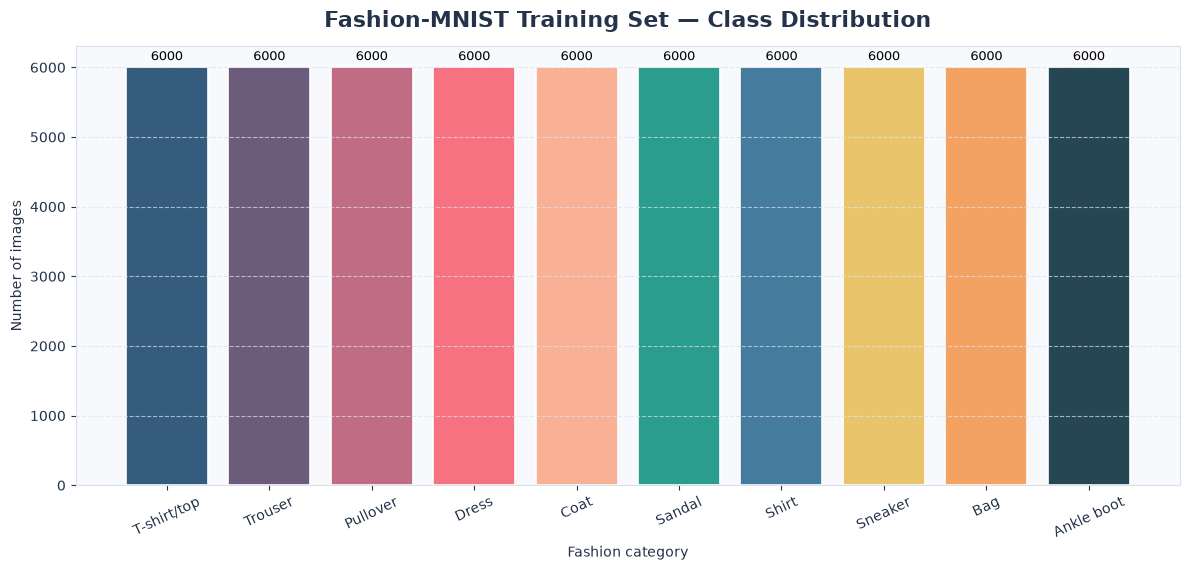

In [18]:
# Matplotlib: class distribution with exact count annotations.
fig, ax = plt.subplots(figsize=(12, 5.8))
bars = ax.bar(CLASS_NAMES, train_class_counts.values, color=PALETTE, edgecolor="white", linewidth=1.2)
ax.set_title("Fashion-MNIST Training Set — Class Distribution", fontsize=16, pad=14)
ax.set_xlabel("Fashion category")
ax.set_ylabel("Number of images")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", linestyle="--")
ax.bar_label(bars, fmt="%d", padding=3, fontsize=9)
fig.tight_layout()
save_matplotlib(fig, "01_class_distribution_matplotlib.png")
plt.show()
plt.close(fig)

In [19]:
# Plotly: interactive version of the class-distribution chart.
fig = px.bar(
    class_distribution, x="class_name", y="train_count", color="class_name",
    color_discrete_sequence=PALETTE,
    title="Interactive Class Distribution — Training Data",
    labels={"class_name": "Fashion category", "train_count": "Image count"},
)
fig.update_layout(showlegend=False, template="plotly_white", title_x=0.02)
fig.update_traces(hovertemplate="%{x}<br>Images: %{y:,}<extra></extra>")
save_plotly(fig, "02_class_distribution_interactive.html")
fig.show()

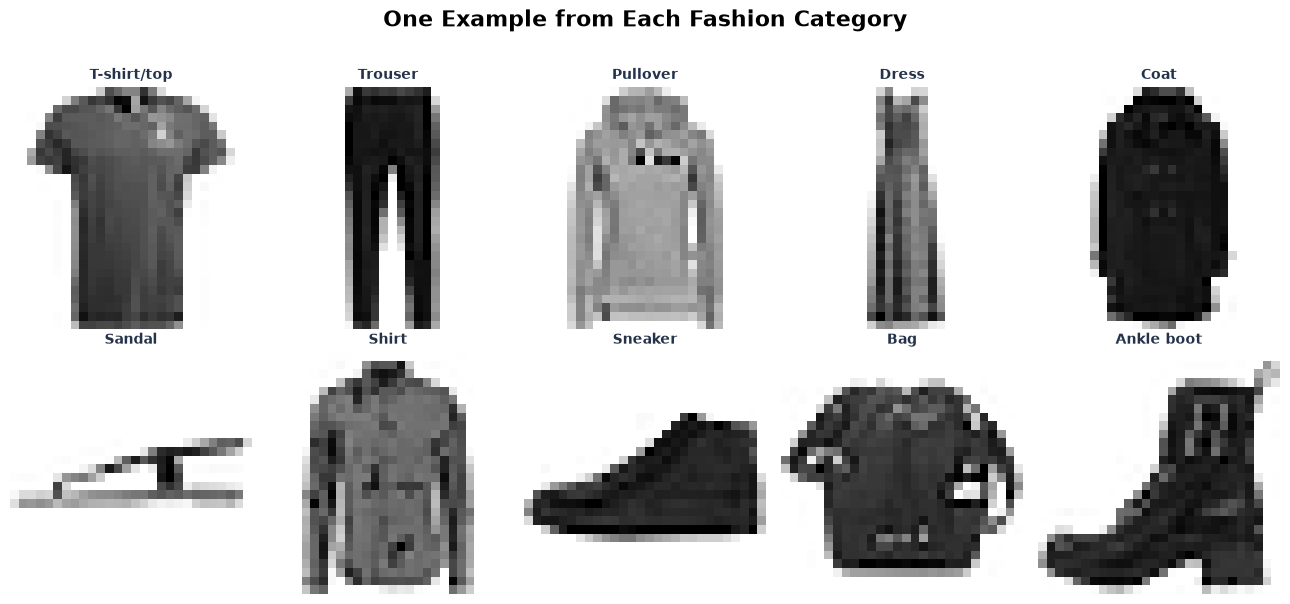

In [20]:
# Display one reproducible image from each class.
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for class_id, ax in enumerate(axes.flat):
    candidates = train_df.index[train_df[LABEL_COLUMN] == class_id].to_numpy()
    selected_index = int(rng.choice(candidates))
    image = train_df.loc[selected_index, PIXEL_COLUMNS].to_numpy(dtype=np.uint8).reshape(28, 28)
    ax.imshow(image, cmap="gray_r", vmin=0, vmax=255)
    ax.set_title(CLASS_NAMES[class_id], fontsize=10)
    ax.axis("off")
fig.suptitle("One Example from Each Fashion Category", fontsize=16, y=1.02)
fig.tight_layout()
save_matplotlib(fig, "03_one_image_per_class.png")
plt.show()
plt.close(fig)

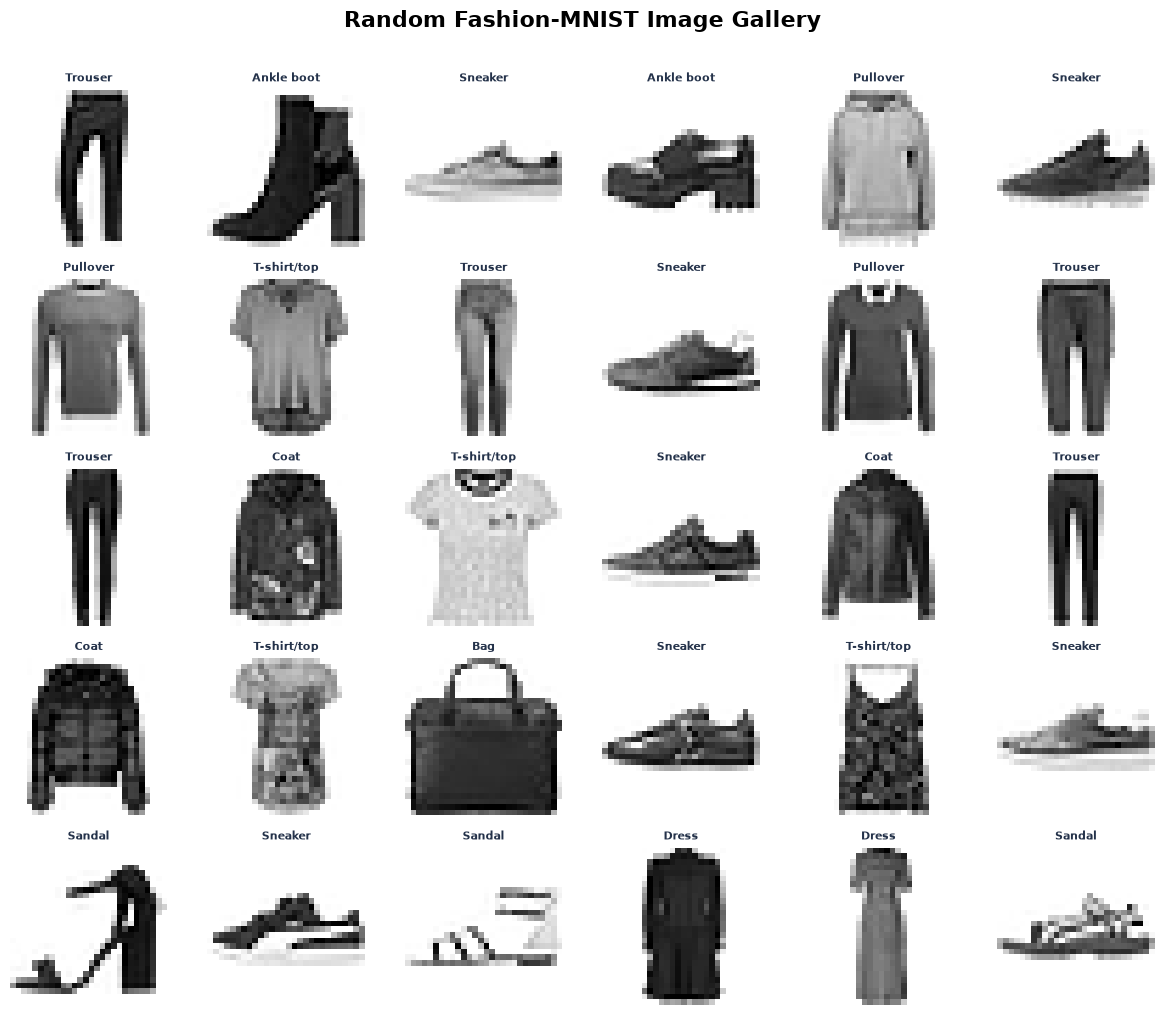

In [21]:
# Display a larger image gallery to inspect within-class variation.
fig, axes = plt.subplots(5, 6, figsize=(12, 10))
for ax in axes.flat:
    row_index = int(rng.integers(0, len(train_df)))
    row = train_df.iloc[row_index]
    ax.imshow(row[PIXEL_COLUMNS].to_numpy(dtype=np.uint8).reshape(28, 28), cmap="gray_r")
    ax.set_title(CLASS_NAMES[int(row[LABEL_COLUMN])], fontsize=8)
    ax.axis("off")
fig.suptitle("Random Fashion-MNIST Image Gallery", fontsize=16, y=1.01)
fig.tight_layout()
save_matplotlib(fig, "04_random_image_gallery.png")
plt.show()
plt.close(fig)

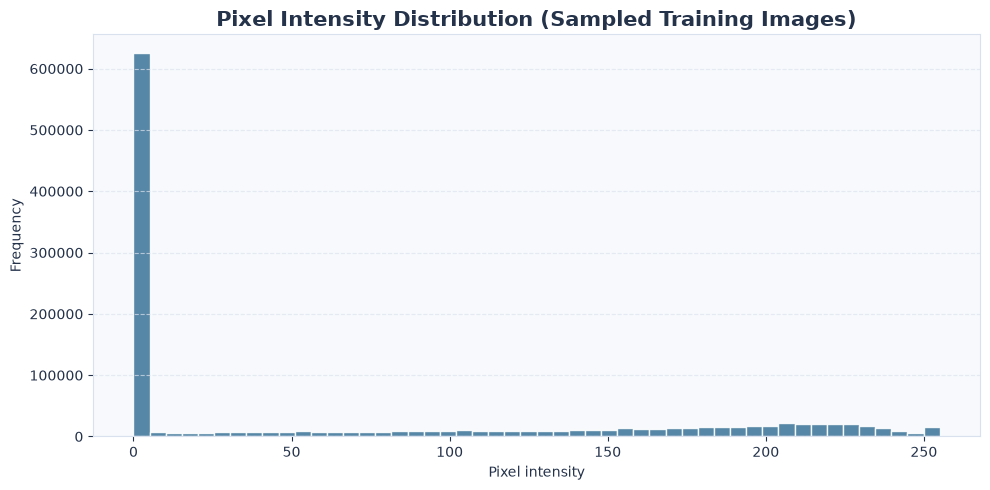

In [22]:
# Inspect the distribution of pixel intensities using a reproducible image sample.
pixel_sample = train_df[PIXEL_COLUMNS].sample(n=min(1500, len(train_df)), random_state=SEED).to_numpy().ravel()
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(pixel_sample, bins=50, color="#457B9D", alpha=0.9, edgecolor="white")
ax.set_title("Pixel Intensity Distribution (Sampled Training Images)", fontsize=15)
ax.set_xlabel("Pixel intensity")
ax.set_ylabel("Frequency")
ax.grid(axis="y", linestyle="--")
fig.tight_layout()
save_matplotlib(fig, "05_pixel_intensity_histogram.png")
plt.show()
plt.close(fig)

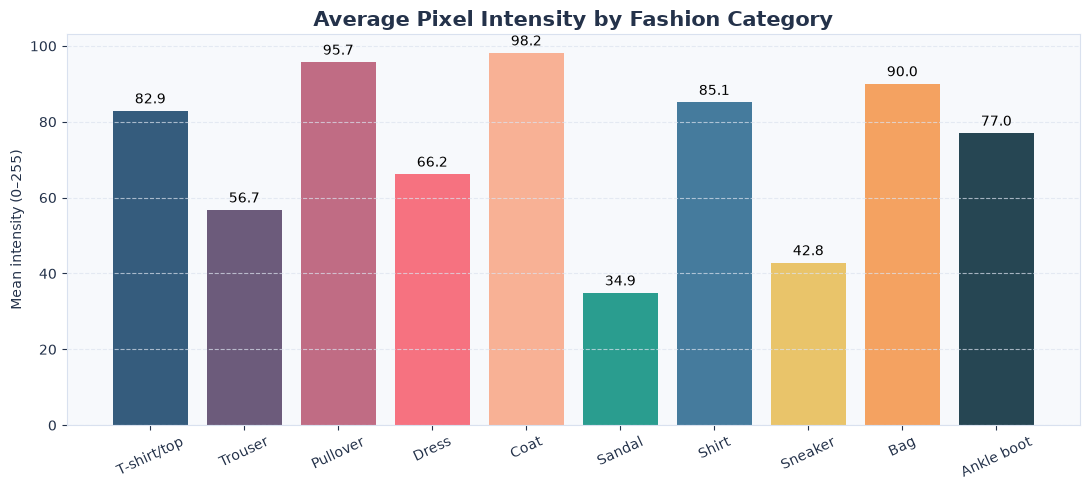

In [23]:
# Compare average image brightness across the ten classes.
class_mean_intensity = []
for class_id in range(NUM_CLASSES):
    class_pixels = train_df.loc[train_df[LABEL_COLUMN] == class_id, PIXEL_COLUMNS].to_numpy(dtype=np.float32)
    class_mean_intensity.append(float(class_pixels.mean()))
brightness_df = pd.DataFrame({"class_name": CLASS_NAMES, "mean_pixel_intensity": class_mean_intensity})
fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(brightness_df["class_name"], brightness_df["mean_pixel_intensity"], color=PALETTE)
ax.set_title("Average Pixel Intensity by Fashion Category", fontsize=15)
ax.set_ylabel("Mean intensity (0–255)")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", linestyle="--")
ax.bar_label(bars, fmt="%.1f", padding=3)
fig.tight_layout()
save_matplotlib(fig, "06_mean_intensity_by_class.png")
plt.show()
plt.close(fig)

In [24]:
# Plotly: interactive class-level brightness comparison.
fig = px.bar(
    brightness_df, x="class_name", y="mean_pixel_intensity", color="class_name",
    color_discrete_sequence=PALETTE, title="Average Pixel Intensity by Class",
    labels={"class_name": "Fashion category", "mean_pixel_intensity": "Mean pixel intensity"},
)
fig.update_layout(showlegend=False, template="plotly_white", title_x=0.02)
save_plotly(fig, "07_mean_intensity_by_class_interactive.html")
fig.show()

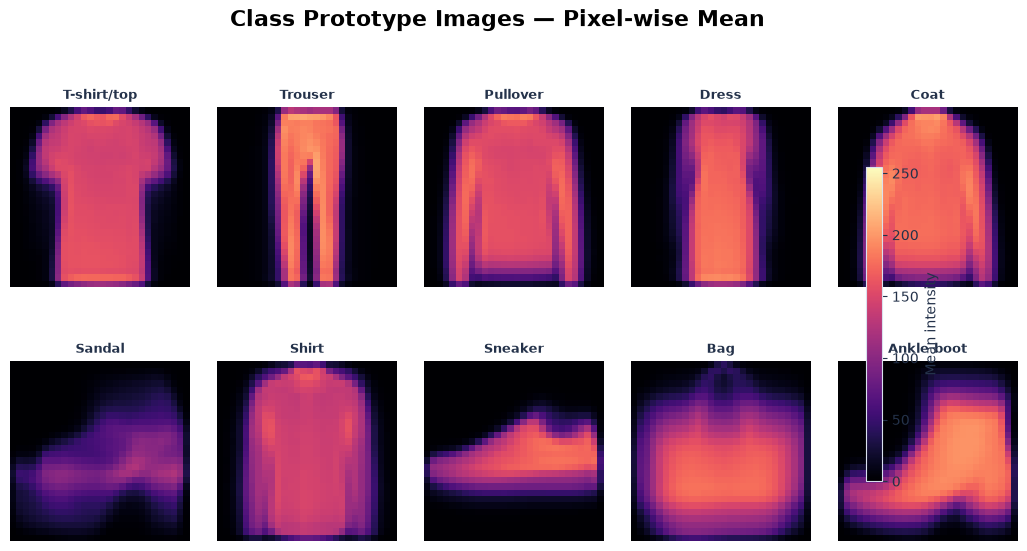

In [25]:
# Visualise class prototype images (pixel-wise mean image for each class).
fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for class_id, ax in enumerate(axes.flat):
    class_pixels = train_df.loc[train_df[LABEL_COLUMN] == class_id, PIXEL_COLUMNS].to_numpy(dtype=np.float32)
    mean_image = class_pixels.mean(axis=0).reshape(28, 28)
    image_plot = ax.imshow(mean_image, cmap="magma", vmin=0, vmax=255)
    ax.set_title(CLASS_NAMES[class_id], fontsize=9)
    ax.axis("off")
fig.suptitle("Class Prototype Images — Pixel-wise Mean", fontsize=16, y=1.02)
fig.colorbar(image_plot, ax=axes.ravel().tolist(), shrink=0.68, label="Mean intensity")
fig.subplots_adjust(top=0.88, wspace=0.15, hspace=0.22)
save_matplotlib(fig, "08_class_mean_prototypes.png")
plt.show()
plt.close(fig)

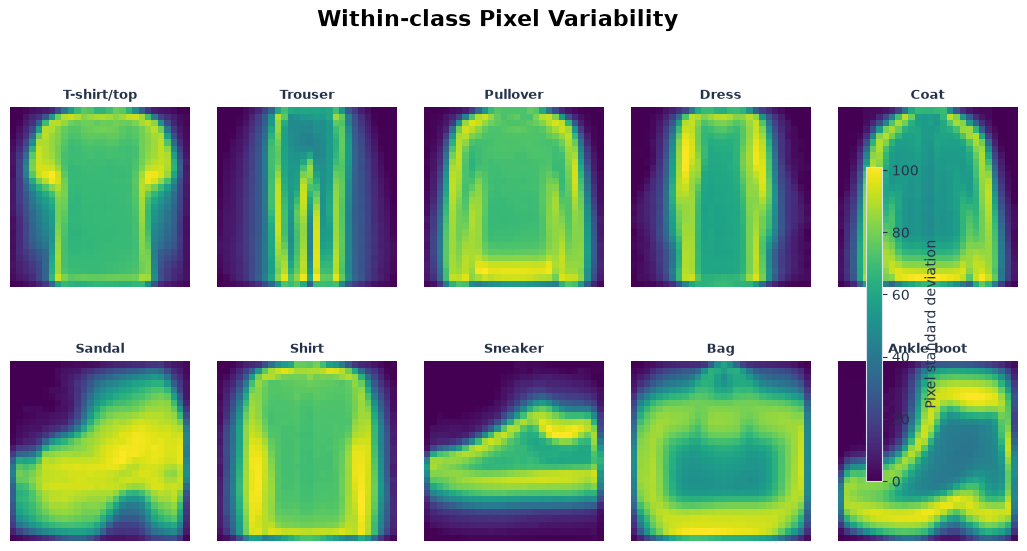

In [26]:
# Visualise within-class pixel variation using standard-deviation images.
fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for class_id, ax in enumerate(axes.flat):
    class_pixels = train_df.loc[train_df[LABEL_COLUMN] == class_id, PIXEL_COLUMNS].to_numpy(dtype=np.float32)
    std_image = class_pixels.std(axis=0).reshape(28, 28)
    image_plot = ax.imshow(std_image, cmap="viridis")
    ax.set_title(CLASS_NAMES[class_id], fontsize=9)
    ax.axis("off")
fig.suptitle("Within-class Pixel Variability", fontsize=16, y=1.02)
fig.colorbar(image_plot, ax=axes.ravel().tolist(), shrink=0.68, label="Pixel standard deviation")
fig.subplots_adjust(top=0.88, wspace=0.15, hspace=0.22)
save_matplotlib(fig, "09_class_pixel_variability.png")
plt.show()
plt.close(fig)

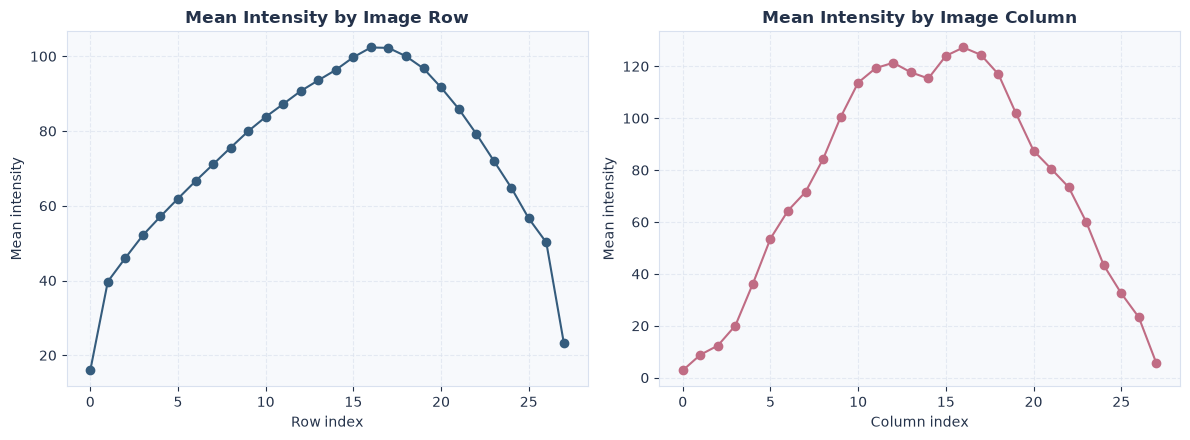

In [27]:
# Examine row-wise and column-wise average intensity across the complete training set.
all_training_pixels = train_df[PIXEL_COLUMNS].to_numpy(dtype=np.float32).reshape(-1, 28, 28)
mean_image_all = all_training_pixels.mean(axis=0)
row_profile = mean_image_all.mean(axis=1)
column_profile = mean_image_all.mean(axis=0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(np.arange(28), row_profile, marker="o", color="#355C7D")
axes[0].set_title("Mean Intensity by Image Row")
axes[0].set_xlabel("Row index")
axes[0].set_ylabel("Mean intensity")
axes[0].grid(True, linestyle="--")
axes[1].plot(np.arange(28), column_profile, marker="o", color="#C06C84")
axes[1].set_title("Mean Intensity by Image Column")
axes[1].set_xlabel("Column index")
axes[1].set_ylabel("Mean intensity")
axes[1].grid(True, linestyle="--")
fig.tight_layout()
save_matplotlib(fig, "10_average_row_column_profiles.png")
plt.show()
plt.close(fig)

## 4. Prepare the modelling splits

The supplied test file remains untouched until final evaluation. The original training file is split in a stratified manner so every class is represented proportionally in the training and validation subsets.

In [28]:
# Separate the complete training feature matrix and labels.
X_all_raw = train_df[PIXEL_COLUMNS].to_numpy(dtype=np.float32)
y_all = train_df[LABEL_COLUMN].to_numpy(dtype=np.int64)
X_test_raw = test_df[PIXEL_COLUMNS].to_numpy(dtype=np.float32)
y_test = test_df[LABEL_COLUMN].to_numpy(dtype=np.int64)
print("Full training feature matrix:", X_all_raw.shape)
print("Held-out test feature matrix :", X_test_raw.shape)

Full training feature matrix: (60000, 784)
Held-out test feature matrix : (10000, 784)


In [29]:
# Create stratified training and validation subsets from the training CSV.
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_all_raw,
    y_all,
    test_size=VALIDATION_SIZE,
    random_state=SEED,
    stratify=y_all,
)
print(f"Train      : {X_train_raw.shape[0]:,} images")
print(f"Validation : {X_val_raw.shape[0]:,} images")
print(f"Test       : {X_test_raw.shape[0]:,} images (separate supplied CSV)")

Train      : 54,000 images
Validation : 6,000 images
Test       : 10,000 images (separate supplied CSV)


In [30]:
# Normalize pixel values to [0, 1] for both scikit-learn and the ANN.
X_train = X_train_raw / 255.0
X_val = X_val_raw / 255.0
X_test = X_test_raw / 255.0
for split_name, features in [("train", X_train), ("validation", X_val), ("test", X_test)]:
    print(f"{split_name:<10} shape={features.shape}, range=({features.min():.3f}, {features.max():.3f})")

train      shape=(54000, 784), range=(0.000, 1.000)
validation shape=(6000, 784), range=(0.000, 1.000)
test       shape=(10000, 784), range=(0.000, 1.000)


In [31]:
# Confirm that stratification preserved class proportions across the splits.
split_distribution = pd.DataFrame({
    "class_name": CLASS_NAMES,
    "train": np.bincount(y_train, minlength=NUM_CLASSES),
    "validation": np.bincount(y_val, minlength=NUM_CLASSES),
    "test": np.bincount(y_test, minlength=NUM_CLASSES),
})
display(split_distribution)

,class_name,train,validation,test
0,T-shirt/top,5400,600,1000
1,Trouser,5400,600,1000
2,Pullover,5400,600,1000
3,Dress,5400,600,1000
4,Coat,5400,600,1000
5,Sandal,5400,600,1000
6,Shirt,5400,600,1000
7,Sneaker,5400,600,1000
8,Bag,5400,600,1000
9,Ankle boot,5400,600,1000


In [32]:
# Visualise train, validation, and test sample counts by category.
plot_split = split_distribution.melt(id_vars="class_name", var_name="split", value_name="image_count")
fig = px.bar(
    plot_split, x="class_name", y="image_count", color="split", barmode="group",
    title="Class Coverage Across Train, Validation, and Test Splits",
    color_discrete_sequence=["#355C7D", "#F4A261", "#2A9D8F"],
)
fig.update_layout(template="plotly_white", title_x=0.02, xaxis_title="Fashion category", yaxis_title="Image count")
save_plotly(fig, "11_split_class_distribution.html")
fig.show()

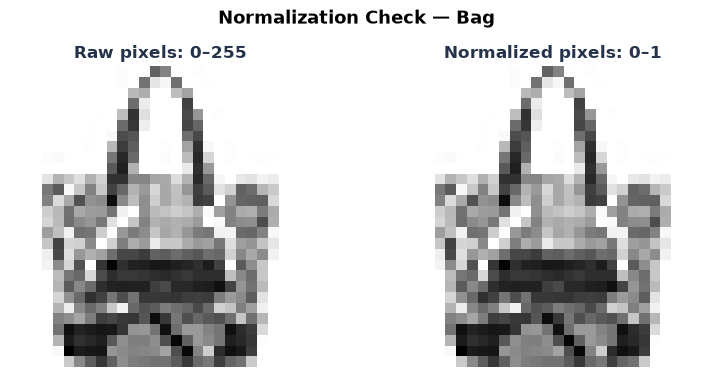

In [33]:
# Compare a raw image with its normalized representation.
normalization_index = 23
raw_image = X_train_raw[normalization_index].reshape(28, 28)
normalized_image = X_train[normalization_index].reshape(28, 28)
fig, axes = plt.subplots(1, 2, figsize=(8, 3.8))
axes[0].imshow(raw_image, cmap="gray_r", vmin=0, vmax=255)
axes[0].set_title("Raw pixels: 0–255")
axes[1].imshow(normalized_image, cmap="gray_r", vmin=0, vmax=1)
axes[1].set_title("Normalized pixels: 0–1")
for ax in axes:
    ax.axis("off")
fig.suptitle(f"Normalization Check — {CLASS_NAMES[int(y_train[normalization_index])]}", fontsize=13)
fig.tight_layout()
save_matplotlib(fig, "12_raw_vs_normalized_image.png")
plt.show()
plt.close(fig)

## 5. Dimensionality reduction with PCA

PCA is used here for exploratory analysis, not as a replacement for the full 784-pixel model inputs. A reproducible subset keeps the visual exploration manageable on standard laptops.

In [34]:
# Fit PCA on a reproducible subset of the normalized training data.
pca_sample_size = min(MAX_PCA_SAMPLES, len(X_train))
pca_sample_indices = rng.choice(len(X_train), size=pca_sample_size, replace=False)
X_pca_sample = X_train[pca_sample_indices]
y_pca_sample = y_train[pca_sample_indices]
pca_model = PCA(n_components=PCA_COMPONENTS, svd_solver="randomized", random_state=SEED)
X_pca = pca_model.fit_transform(X_pca_sample)
print("PCA input shape :", X_pca_sample.shape)
print("PCA output shape:", X_pca.shape)

PCA input shape : (12000, 784)
PCA output shape: (12000, 50)


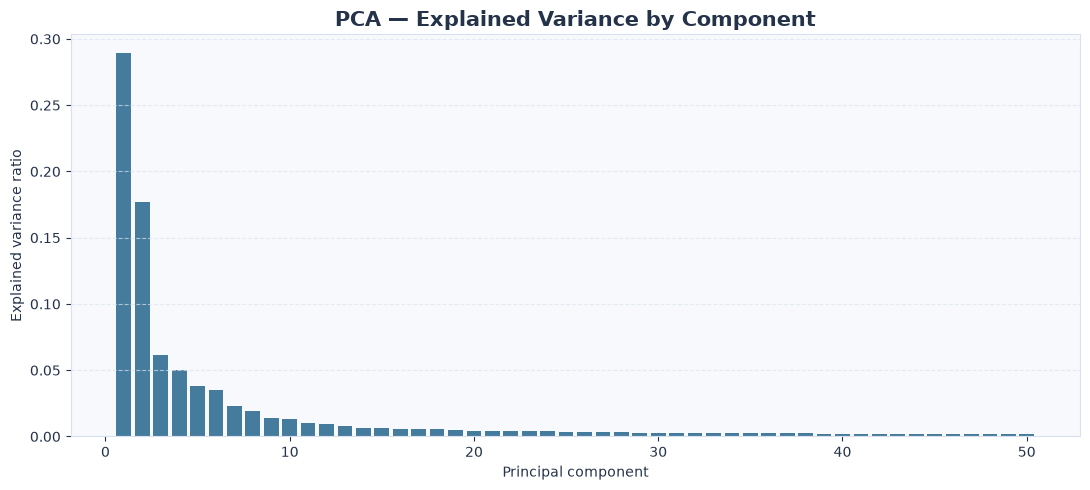

In [35]:
# Plot the variance explained by each principal component.
explained_variance_df = pd.DataFrame({
    "component": np.arange(1, PCA_COMPONENTS + 1),
    "explained_variance_ratio": pca_model.explained_variance_ratio_,
})
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(explained_variance_df["component"], explained_variance_df["explained_variance_ratio"], color="#457B9D")
ax.set_title("PCA — Explained Variance by Component", fontsize=15)
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio")
ax.grid(axis="y", linestyle="--")
fig.tight_layout()
save_matplotlib(fig, "13_pca_explained_variance.png")
plt.show()
plt.close(fig)

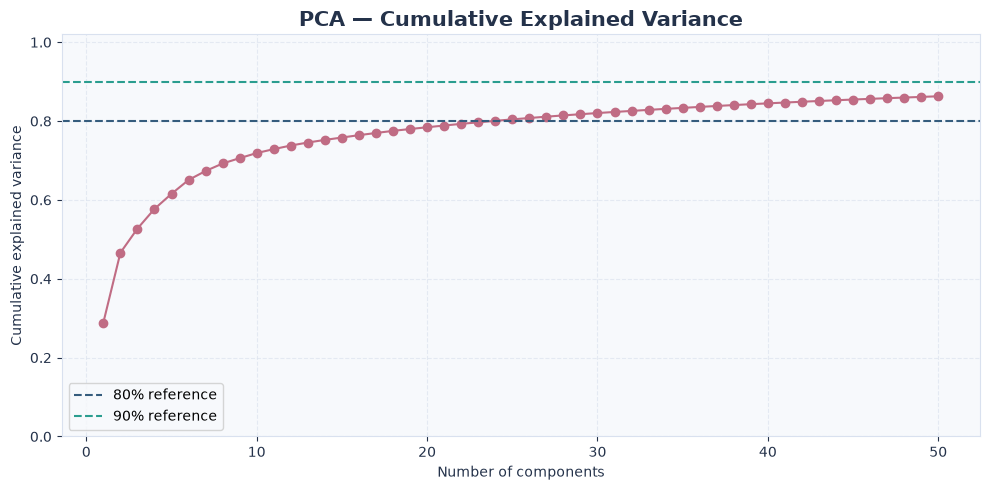

In [36]:
# Plot cumulative explained variance to show how information accumulates.
explained_variance_df["cumulative_variance"] = explained_variance_df["explained_variance_ratio"].cumsum()
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(explained_variance_df["component"], explained_variance_df["cumulative_variance"], marker="o", color="#C06C84")
ax.axhline(0.80, color="#355C7D", linestyle="--", label="80% reference")
ax.axhline(0.90, color="#2A9D8F", linestyle="--", label="90% reference")
ax.set_ylim(0, 1.02)
ax.set_title("PCA — Cumulative Explained Variance", fontsize=15)
ax.set_xlabel("Number of components")
ax.set_ylabel("Cumulative explained variance")
ax.legend()
ax.grid(True, linestyle="--")
fig.tight_layout()
save_matplotlib(fig, "14_pca_cumulative_variance.png")
plt.show()
plt.close(fig)

In [37]:
# Project PCA results into two dimensions for a class-coloured exploratory view.
pca_2d_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Class": [CLASS_NAMES[int(label)] for label in y_pca_sample],
})
fig = px.scatter(
    pca_2d_df, x="PC1", y="PC2", color="Class", opacity=0.58,
    color_discrete_sequence=PALETTE, title="Fashion-MNIST — PCA Projection (2D)",
)
fig.update_layout(template="plotly_white", title_x=0.02, legend_title="Category")
save_plotly(fig, "15_pca_2d_class_projection.html")
fig.show()

C:\Users\as178\AppData\Local\Temp\ipykernel_20864\3365531947.py:10: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


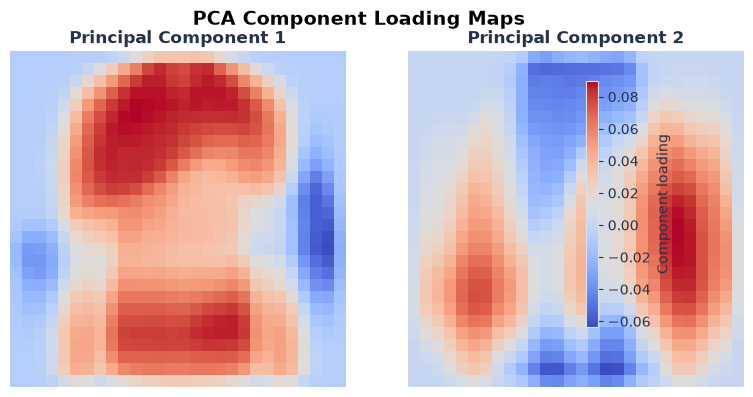

In [38]:
# Visualise the first two PCA component loading patterns as 28×28 images.
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for component_index, ax in enumerate(axes):
    component_image = pca_model.components_[component_index].reshape(28, 28)
    image_plot = ax.imshow(component_image, cmap="coolwarm")
    ax.set_title(f"Principal Component {component_index + 1}")
    ax.axis("off")
fig.colorbar(image_plot, ax=axes.ravel().tolist(), shrink=0.8, label="Component loading")
fig.suptitle("PCA Component Loading Maps", fontsize=14)
fig.tight_layout()
save_matplotlib(fig, "16_pca_component_maps.png")
plt.show()
plt.close(fig)

In [39]:
# Identify the image pixels with the highest variance across the training set.
pixel_variances = X_train.var(axis=0)
top_pixel_indices = np.argsort(pixel_variances)[-20:][::-1]
top_pixels_df = pd.DataFrame({
    "pixel_index": top_pixel_indices,
    "row": top_pixel_indices // 28,
    "column": top_pixel_indices % 28,
    "variance": pixel_variances[top_pixel_indices],
})
display(top_pixels_df)

,pixel_index,row,column,variance
0,43,1,15,0.164915
1,40,1,12,0.164561
2,41,1,13,0.162070
3,42,1,14,0.160748
4,740,26,12,0.158458
5,44,1,16,0.158177
6,739,26,11,0.156845
7,744,26,16,0.156463
8,39,1,11,0.153333
9,745,26,17,0.152939


## 6. scikit-learn baselines

A majority-class dummy model provides a minimum reference point. The SGD classifier then learns a linear decision boundary using the normalized pixel features. The same untouched test set is used for comparison.

In [40]:
# Fit a simple majority-class model to establish a baseline floor.
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)
dummy_test_predictions = dummy_model.predict(X_test)
dummy_test_accuracy = accuracy_score(y_test, dummy_test_predictions)
print(f"Dummy classifier test accuracy: {dummy_test_accuracy:.2%}")

Dummy classifier test accuracy: 10.00%


In [41]:
# Configure a scalable linear classifier with probabilistic outputs.
sgd_model = SGDClassifier(
    loss="log_loss",
    penalty="l2",
    alpha=1e-4,
    max_iter=SGD_MAX_ITER,
    tol=1e-3,
    early_stopping=True,
    validation_fraction=0.10,
    n_iter_no_change=4,
    random_state=SEED,
    n_jobs=-1,
)
print(sgd_model)

SGDClassifier(early_stopping=True, loss='log_loss', max_iter=20,
              n_iter_no_change=4, n_jobs=-1, random_state=42)


In [42]:
# Train the scikit-learn SGD model and record training time.
sgd_start_time = time.time()
sgd_model.fit(X_train, y_train)
sgd_training_seconds = time.time() - sgd_start_time
print(f"SGD training time: {sgd_training_seconds:.1f} seconds")
print(f"Iterations used  : {sgd_model.n_iter_}")

SGD training time: 2.7 seconds
Iterations used  : 12


In [43]:
# Predict test labels and class probabilities with the trained SGD classifier.
sgd_test_predictions = sgd_model.predict(X_test)
sgd_test_probabilities = sgd_model.predict_proba(X_test)
sgd_test_accuracy = accuracy_score(y_test, sgd_test_predictions)
print(f"SGD classifier test accuracy: {sgd_test_accuracy:.2%}")
print("Probability matrix shape    :", sgd_test_probabilities.shape)

SGD classifier test accuracy: 82.55%
Probability matrix shape    : (10000, 10)


In [44]:
# Generate the full scikit-learn classification report.
sgd_report_dict = classification_report(
    y_test, sgd_test_predictions,
    labels=np.arange(NUM_CLASSES), target_names=CLASS_NAMES,
    output_dict=True, zero_division=0,
)
sgd_report_df = pd.DataFrame(sgd_report_dict).T
display(sgd_report_df.style.format({"precision": "{:.3f}", "recall": "{:.3f}", "f1-score": "{:.3f}", "support": "{:.0f}"}))

,precision,recall,f1-score,support
T-shirt/top,0.882,0.663,0.757,1000
Trouser,0.940,0.978,0.959,1000
Pullover,0.782,0.716,0.747,1000
Dress,0.810,0.872,0.840,1000
Coat,0.792,0.703,0.745,1000
Sandal,0.893,0.916,0.904,1000
Shirt,0.542,0.701,0.611,1000
Sneaker,0.903,0.861,0.882,1000
Bag,0.901,0.924,0.912,1000
Ankle boot,0.895,0.921,0.908,1000


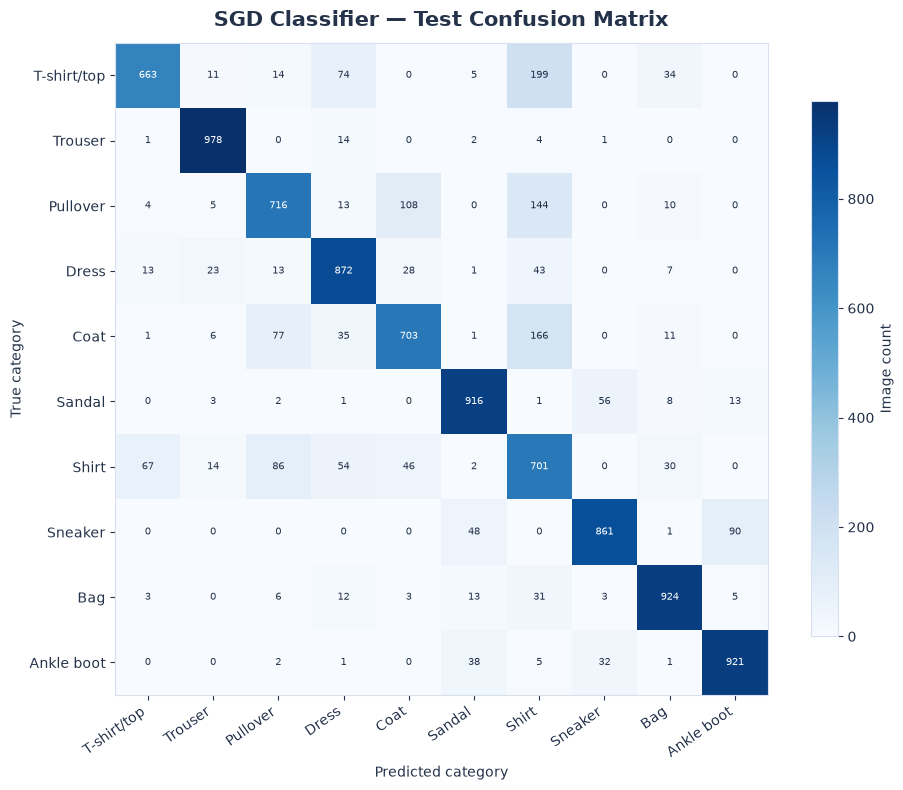

In [45]:
# Matplotlib: confusion matrix for the scikit-learn baseline.
sgd_cm = confusion_matrix(y_test, sgd_test_predictions, labels=np.arange(NUM_CLASSES))
fig, ax = plt.subplots(figsize=(10, 8))
image_plot = ax.imshow(sgd_cm, cmap="Blues")
ax.set_title("SGD Classifier — Test Confusion Matrix", fontsize=15, pad=12)
ax.set_xlabel("Predicted category")
ax.set_ylabel("True category")
ax.set_xticks(np.arange(NUM_CLASSES), labels=CLASS_NAMES, rotation=35, ha="right")
ax.set_yticks(np.arange(NUM_CLASSES), labels=CLASS_NAMES)
for row in range(NUM_CLASSES):
    for col in range(NUM_CLASSES):
        value = sgd_cm[row, col]
        ax.text(col, row, f"{value:,}", ha="center", va="center", fontsize=7,
                color="white" if value > sgd_cm.max() * 0.55 else TEXT_COLOR)
fig.colorbar(image_plot, ax=ax, shrink=0.82, label="Image count")
fig.tight_layout()
save_matplotlib(fig, "17_sgd_confusion_matrix.png")
plt.show()
plt.close(fig)

In [46]:
# Plotly: interactive confusion matrix for the scikit-learn baseline.
fig = go.Figure(data=go.Heatmap(
    z=sgd_cm,
    x=CLASS_NAMES,
    y=CLASS_NAMES,
    colorscale="Blues",
    hovertemplate="True: %{y}<br>Predicted: %{x}<br>Count: %{z:,}<extra></extra>",
))
fig.update_layout(
    title="SGD Classifier — Interactive Confusion Matrix",
    xaxis_title="Predicted category", yaxis_title="True category",
    template="plotly_white", title_x=0.02,
)
save_plotly(fig, "18_sgd_confusion_matrix_interactive.html")
fig.show()

In [47]:
# Compute class-wise precision, recall, F1-score, and support for the SGD model.
sgd_precision, sgd_recall, sgd_f1, sgd_support = precision_recall_fscore_support(
    y_test, sgd_test_predictions, labels=np.arange(NUM_CLASSES), zero_division=0
)
sgd_class_metrics = pd.DataFrame({
    "class_name": CLASS_NAMES,
    "precision": sgd_precision,
    "recall": sgd_recall,
    "f1_score": sgd_f1,
    "support": sgd_support,
})
display(sgd_class_metrics.style.format({"precision": "{:.3f}", "recall": "{:.3f}", "f1_score": "{:.3f}", "support": "{:,.0f}"}))

,class_name,precision,recall,f1_score,support
0,T-shirt/top,0.882,0.663,0.757,"1,000"
1,Trouser,0.940,0.978,0.959,"1,000"
2,Pullover,0.782,0.716,0.747,"1,000"
3,Dress,0.810,0.872,0.840,"1,000"
4,Coat,0.792,0.703,0.745,"1,000"
5,Sandal,0.893,0.916,0.904,"1,000"
6,Shirt,0.542,0.701,0.611,"1,000"
7,Sneaker,0.903,0.861,0.882,"1,000"
8,Bag,0.901,0.924,0.912,"1,000"
9,Ankle boot,0.895,0.921,0.908,"1,000"


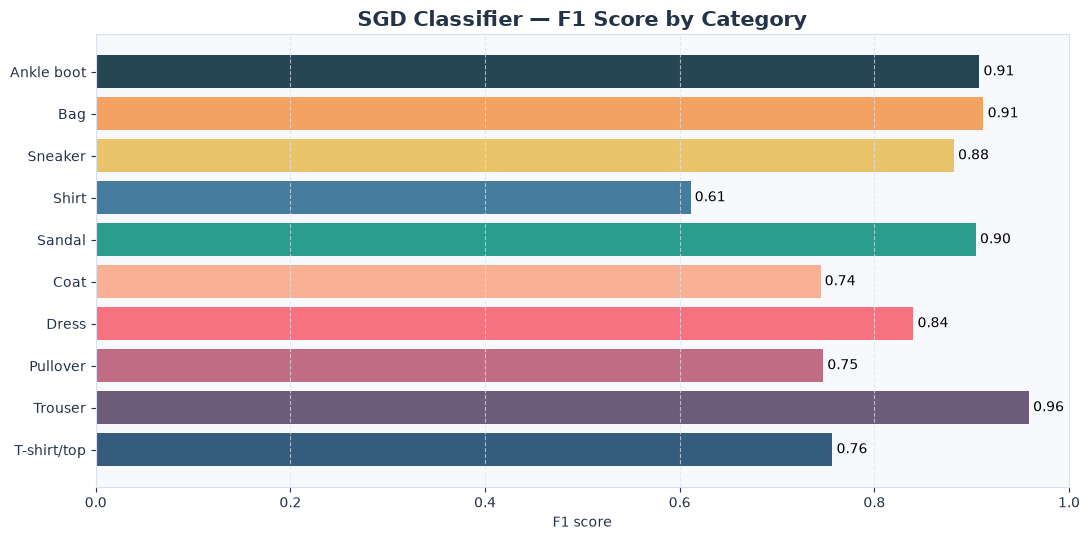

In [48]:
# Compare class-wise F1 scores for the SGD model.
fig, ax = plt.subplots(figsize=(11, 5.5))
bars = ax.barh(sgd_class_metrics["class_name"], sgd_class_metrics["f1_score"], color=PALETTE)
ax.set_xlim(0, 1)
ax.set_title("SGD Classifier — F1 Score by Category", fontsize=15)
ax.set_xlabel("F1 score")
ax.grid(axis="x", linestyle="--")
ax.bar_label(bars, fmt="%.2f", padding=3)
fig.tight_layout()
save_matplotlib(fig, "19_sgd_per_class_f1.png")
plt.show()
plt.close(fig)

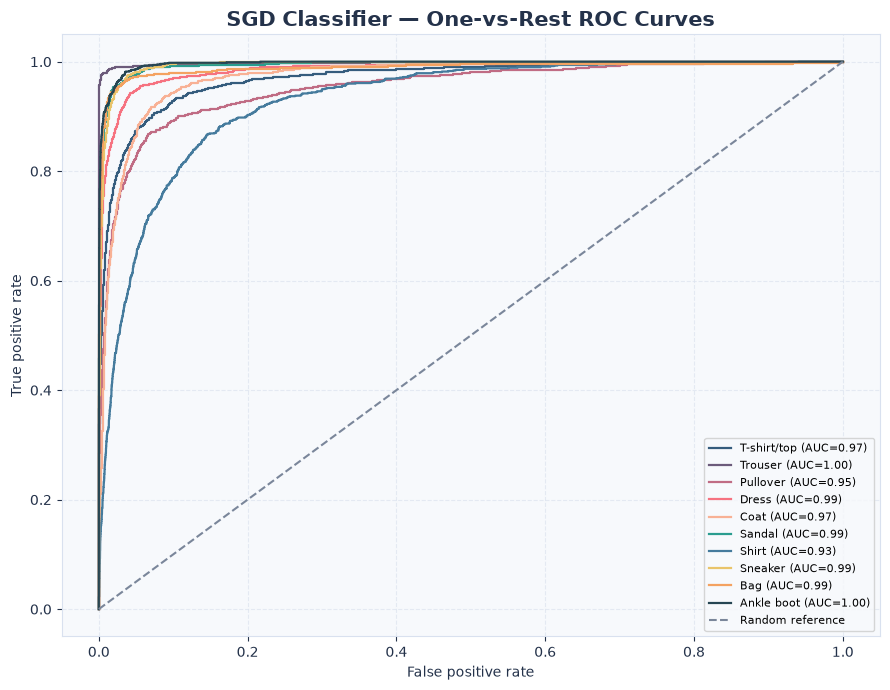

In [49]:
# Calculate one-vs-rest ROC curves and AUC values for the SGD model.
y_test_binary = label_binarize(y_test, classes=np.arange(NUM_CLASSES))
sgd_roc_rows = []
fig, ax = plt.subplots(figsize=(9, 7))
for class_id in range(NUM_CLASSES):
    fpr, tpr, _ = roc_curve(y_test_binary[:, class_id], sgd_test_probabilities[:, class_id])
    class_auc = auc(fpr, tpr)
    sgd_roc_rows.append({"class_name": CLASS_NAMES[class_id], "auc": class_auc})
    ax.plot(fpr, tpr, label=f"{CLASS_NAMES[class_id]} (AUC={class_auc:.2f})", color=PALETTE[class_id], linewidth=1.6)
ax.plot([0, 1], [0, 1], linestyle="--", color="#7A869A", label="Random reference")
ax.set_title("SGD Classifier — One-vs-Rest ROC Curves", fontsize=15)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend(loc="lower right", fontsize=8)
ax.grid(True, linestyle="--")
fig.tight_layout()
save_matplotlib(fig, "20_sgd_roc_curves.png")
plt.show()
plt.close(fig)
sgd_roc_df = pd.DataFrame(sgd_roc_rows)

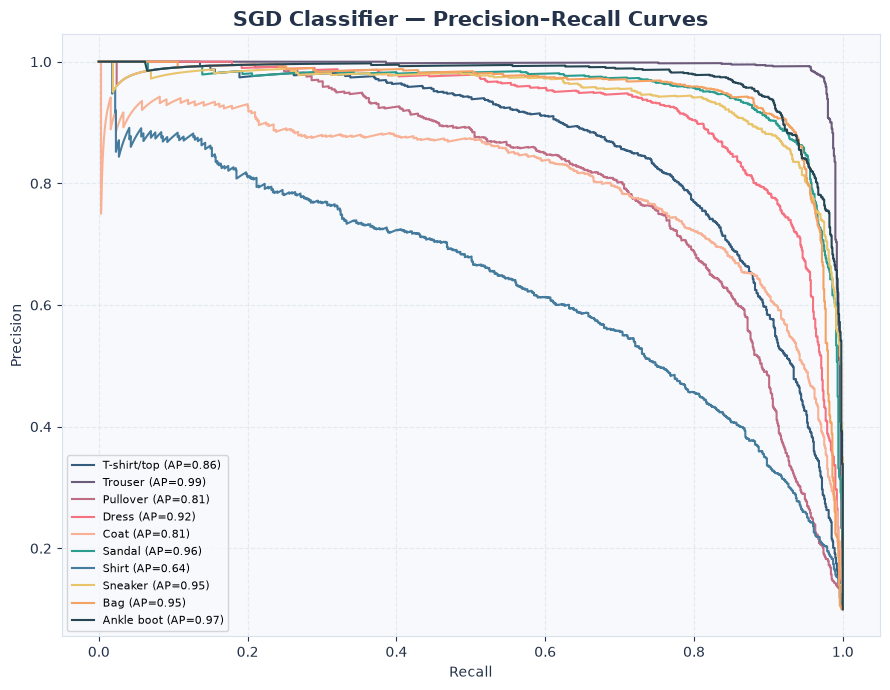

In [50]:
# Compute per-class precision-recall curves and average precision for the SGD model.
sgd_pr_rows = []
fig, ax = plt.subplots(figsize=(9, 7))
for class_id in range(NUM_CLASSES):
    precision_values, recall_values, _ = precision_recall_curve(
        y_test_binary[:, class_id], sgd_test_probabilities[:, class_id]
    )
    average_precision = average_precision_score(y_test_binary[:, class_id], sgd_test_probabilities[:, class_id])
    sgd_pr_rows.append({"class_name": CLASS_NAMES[class_id], "average_precision": average_precision})
    ax.plot(recall_values, precision_values, color=PALETTE[class_id], linewidth=1.5,
            label=f"{CLASS_NAMES[class_id]} (AP={average_precision:.2f})")
ax.set_title("SGD Classifier — Precision–Recall Curves", fontsize=15)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend(loc="lower left", fontsize=8)
ax.grid(True, linestyle="--")
fig.tight_layout()
save_matplotlib(fig, "21_sgd_precision_recall_curves.png")
plt.show()
plt.close(fig)
sgd_pr_df = pd.DataFrame(sgd_pr_rows)

In [51]:
# Summarise the classical baseline results in a compact scorecard.
sgd_baseline_scorecard = pd.DataFrame([
    {"model": "DummyClassifier", "test_accuracy": dummy_test_accuracy, "training_seconds": np.nan},
    {"model": "SGDClassifier", "test_accuracy": sgd_test_accuracy, "training_seconds": sgd_training_seconds},
])
display(sgd_baseline_scorecard.style.format({"test_accuracy": "{:.2%}", "training_seconds": "{:.1f}"}))

,model,test_accuracy,training_seconds
0,DummyClassifier,10.00%,nan
1,SGDClassifier,82.55%,2.7


In [52]:
# Review the most confident scikit-learn errors for targeted inspection.
sgd_error_indices = np.flatnonzero(sgd_test_predictions != y_test)
sgd_error_confidence = sgd_test_probabilities.max(axis=1)
sgd_error_review = pd.DataFrame({
    "test_index": sgd_error_indices,
    "true_class": [CLASS_NAMES[int(y_test[i])] for i in sgd_error_indices],
    "predicted_class": [CLASS_NAMES[int(sgd_test_predictions[i])] for i in sgd_error_indices],
    "confidence": sgd_error_confidence[sgd_error_indices],
})
sgd_error_review = sgd_error_review.sort_values("confidence", ascending=False).head(15)
display(sgd_error_review.style.format({"confidence": "{:.1%}"}))

,test_index,true_class,predicted_class,confidence
1605,9181,Sneaker,Ankle boot,100.0%
1531,8812,Shirt,Bag,100.0%
174,1048,Shirt,Pullover,100.0%
994,5779,Ankle boot,Sneaker,100.0%
210,1282,Sandal,Ankle boot,100.0%
223,1343,Pullover,Bag,100.0%
1689,9692,T-shirt/top,Bag,100.0%
583,3399,Sneaker,Ankle boot,100.0%
1409,8059,Coat,Shirt,100.0%
1459,8325,Sandal,Bag,100.0%


In [53]:
# Rank the most frequent off-diagonal confusions made by the SGD classifier.
sgd_confusion_pairs = []
for true_id in range(NUM_CLASSES):
    for predicted_id in range(NUM_CLASSES):
        if true_id != predicted_id and sgd_cm[true_id, predicted_id] > 0:
            sgd_confusion_pairs.append({
                "true_class": CLASS_NAMES[true_id],
                "predicted_class": CLASS_NAMES[predicted_id],
                "confusion": f"{CLASS_NAMES[true_id]} → {CLASS_NAMES[predicted_id]}",
                "count": int(sgd_cm[true_id, predicted_id]),
            })
sgd_confusion_pairs_df = pd.DataFrame(sgd_confusion_pairs).sort_values("count", ascending=False).head(15)
display(sgd_confusion_pairs_df)

,true_class,predicted_class,confusion,count
4,T-shirt/top,Shirt,T-shirt/top → Shirt,199
29,Coat,Shirt,Coat → Shirt,166
15,Pullover,Shirt,Pullover → Shirt,144
14,Pullover,Coat,Pullover → Coat,108
47,Sneaker,Ankle boot,Sneaker → Ankle boot,90
40,Shirt,Pullover,Shirt → Pullover,86
26,Coat,Pullover,Coat → Pullover,77
2,T-shirt/top,Dress,T-shirt/top → Dress,74
38,Shirt,T-shirt/top,Shirt → T-shirt/top,67
35,Sandal,Sneaker,Sandal → Sneaker,56


## 7. PyTorch artificial neural network

The ANN receives flattened 28×28 images and predicts one of ten categories. Batch normalisation, GELU activations, dropout, AdamW, a validation-driven learning-rate scheduler, and early stopping are included to make the training process stable and inspectable.

In [54]:
# Wrap NumPy arrays in a lightweight PyTorch Dataset.
class FashionArrayDataset(Dataset):
    def __init__(self, features, labels):
        if len(features) != len(labels):
            raise ValueError("Features and labels must have matching row counts.")
        self.features = torch.tensor(features, dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.features[index], self.labels[index]

train_dataset = FashionArrayDataset(X_train, y_train)
val_dataset = FashionArrayDataset(X_val, y_val)
test_dataset = FashionArrayDataset(X_test, y_test)
print(f"Dataset objects created: train={len(train_dataset):,}, val={len(val_dataset):,}, test={len(test_dataset):,}")

Dataset objects created: train=54,000, val=6,000, test=10,000


In [55]:
# Create DataLoaders with reproducible shuffling for the training subset.
loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"),
                          generator=loader_generator)
val_loader = DataLoader(val_dataset, batch_size=EVAL_BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"))
test_loader = DataLoader(test_dataset, batch_size=EVAL_BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"))
print(f"Train batches: {len(train_loader)} | Validation batches: {len(val_loader)} | Test batches: {len(test_loader)}")

Train batches: 211 | Validation batches: 12 | Test batches: 20


In [56]:
# Inspect one mini-batch to verify tensor dimensions and label types.
batch_features, batch_labels = next(iter(train_loader))
print("Feature batch:", tuple(batch_features.shape), batch_features.dtype)
print("Label batch  :", tuple(batch_labels.shape), batch_labels.dtype)
print("Pixel range  :", float(batch_features.min()), "to", float(batch_features.max()))

Feature batch: (256, 784) torch.float32
Label batch  : (256,) torch.int64
Pixel range  : 0.0 to 1.0


In [57]:
# Define the fully connected ANN with batch normalisation and dropout.
class FashionANN(nn.Module):
    def __init__(self, input_features=784, num_classes=10, dropout_rate=0.30):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_features, 512),
            nn.BatchNorm1d(512),
            nn.GELU(),
            nn.Dropout(dropout_rate),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.GELU(),
            nn.Dropout(dropout_rate),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.GELU(),
            nn.Dropout(dropout_rate / 2),
            nn.Linear(128, num_classes),
        )

    def forward(self, features):
        return self.network(features)

print("ANN architecture defined.")

ANN architecture defined.


In [58]:
# Instantiate the ANN and move it to the available compute device.
model = FashionANN(dropout_rate=DROPOUT_RATE).to(DEVICE)
print(model)

FashionANN(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): GELU(approximate='none')
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=256, out_features=128, bias=True)
    (9): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): GELU(approximate='none')
    (11): Dropout(p=0.15, inplace=False)
    (12): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [59]:
# Count trainable parameters and test the expected output dimensions.
trainable_parameters = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
with torch.no_grad():
    smoke_test_logits = model(batch_features[:8].to(DEVICE))
print(f"Trainable parameters: {trainable_parameters:,}")
print("Smoke-test output shape:", tuple(smoke_test_logits.shape), "(expected: 8 × 10)")

Trainable parameters: 569,226
Smoke-test output shape: (8, 10) (expected: 8 × 10)


In [60]:
# Configure the multiclass loss, AdamW optimizer, and validation-based scheduler.
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=2, min_lr=1e-6
)
print("Loss, optimizer, and learning-rate scheduler are ready.")

Loss, optimizer, and learning-rate scheduler are ready.


In [61]:
def train_one_epoch(model, loader, criterion, optimizer):
    """Train for one epoch and return sample-weighted loss and accuracy."""
    model.train()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0
    for features, labels in loader:
        features = features.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(features)
        loss = criterion(logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
        optimizer.step()
        total_loss += loss.item() * labels.size(0)
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_examples += labels.size(0)
    return {"loss": total_loss / total_examples, "accuracy": total_correct / total_examples}

In [62]:
def evaluate_one_epoch(model, loader, criterion):
    """Evaluate without gradient tracking and return loss and accuracy."""
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0
    with torch.no_grad():
        for features, labels in loader:
            features = features.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            logits = model(features)
            loss = criterion(logits, labels)
            total_loss += loss.item() * labels.size(0)
            total_correct += (logits.argmax(dim=1) == labels).sum().item()
            total_examples += labels.size(0)
    return {"loss": total_loss / total_examples, "accuracy": total_correct / total_examples}

In [63]:
# Train the ANN with best-validation-loss checkpointing and early stopping.
history = {"epoch": [], "train_loss": [], "train_accuracy": [],
           "val_loss": [], "val_accuracy": [], "learning_rate": []}
best_val_loss = float("inf")
best_val_accuracy = 0.0
best_epoch = 0
best_model_state = copy.deepcopy(model.state_dict())
epochs_without_improvement = 0
training_start_time = time.time()

for epoch in range(1, MAX_EPOCHS + 1):
    epoch_start = time.time()
    train_metrics = train_one_epoch(model, train_loader, criterion, optimizer)
    val_metrics = evaluate_one_epoch(model, val_loader, criterion)
    current_lr = optimizer.param_groups[0]["lr"]
    scheduler.step(val_metrics["loss"])

    history["epoch"].append(epoch)
    history["train_loss"].append(train_metrics["loss"])
    history["train_accuracy"].append(train_metrics["accuracy"])
    history["val_loss"].append(val_metrics["loss"])
    history["val_accuracy"].append(val_metrics["accuracy"])
    history["learning_rate"].append(current_lr)

    if val_metrics["loss"] < best_val_loss:
        best_val_loss = val_metrics["loss"]
        best_val_accuracy = val_metrics["accuracy"]
        best_epoch = epoch
        best_model_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
        checkpoint_note = "★ best checkpoint"
    else:
        epochs_without_improvement += 1
        checkpoint_note = ""

    elapsed = time.time() - epoch_start
    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"train loss {train_metrics['loss']:.4f} | train acc {train_metrics['accuracy']:.2%} | "
        f"val loss {val_metrics['loss']:.4f} | val acc {val_metrics['accuracy']:.2%} | "
        f"lr {current_lr:.2e} | {elapsed:.1f}s {checkpoint_note}"
    )
    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("Early stopping: validation loss did not improve.")
        break

training_duration_seconds = time.time() - training_start_time
model.load_state_dict(best_model_state)
model.eval()
print(f"Training completed in {training_duration_seconds / 60:.2f} minutes; best epoch = {best_epoch}.")

Epoch 01/12 | train loss 0.5374 | train acc 82.09% | val loss 0.4090 | val acc 84.08% | lr 1.00e-03 | 5.4s ★ best checkpoint
Epoch 02/12 | train loss 0.3767 | train acc 86.28% | val loss 0.3443 | val acc 87.13% | lr 1.00e-03 | 5.3s ★ best checkpoint
Epoch 03/12 | train loss 0.3397 | train acc 87.65% | val loss 0.3548 | val acc 86.70% | lr 1.00e-03 | 4.9s 
Epoch 04/12 | train loss 0.3159 | train acc 88.39% | val loss 0.3160 | val acc 88.30% | lr 1.00e-03 | 4.9s ★ best checkpoint
Epoch 05/12 | train loss 0.2968 | train acc 89.10% | val loss 0.3296 | val acc 88.07% | lr 1.00e-03 | 4.9s 
Epoch 06/12 | train loss 0.2854 | train acc 89.54% | val loss 0.3188 | val acc 87.98% | lr 1.00e-03 | 4.9s 
Epoch 07/12 | train loss 0.2690 | train acc 90.07% | val loss 0.3219 | val acc 88.23% | lr 1.00e-03 | 4.9s 
Epoch 08/12 | train loss 0.2367 | train acc 91.38% | val loss 0.2960 | val acc 89.08% | lr 5.00e-04 | 4.8s ★ best checkpoint
Epoch 09/12 | train loss 0.2256 | train acc 91.54% | val loss 0.3006

In [64]:
# Convert the training history into a tidy table for display and export.
history_df = pd.DataFrame(history)
display(history_df.style.format({
    "train_loss": "{:.4f}", "train_accuracy": "{:.2%}",
    "val_loss": "{:.4f}", "val_accuracy": "{:.2%}", "learning_rate": "{:.2e}",
}))

,epoch,train_loss,train_accuracy,val_loss,val_accuracy,learning_rate
0,1,0.5374,82.09%,0.4090,84.08%,1.00e-03
1,2,0.3767,86.28%,0.3443,87.13%,1.00e-03
2,3,0.3397,87.65%,0.3548,86.70%,1.00e-03
3,4,0.3159,88.39%,0.3160,88.30%,1.00e-03
4,5,0.2968,89.10%,0.3296,88.07%,1.00e-03
5,6,0.2854,89.54%,0.3188,87.98%,1.00e-03
6,7,0.2690,90.07%,0.3219,88.23%,1.00e-03
7,8,0.2367,91.38%,0.2960,89.08%,5.00e-04
8,9,0.2256,91.54%,0.3006,89.15%,5.00e-04
9,10,0.2192,91.77%,0.2982,89.03%,5.00e-04


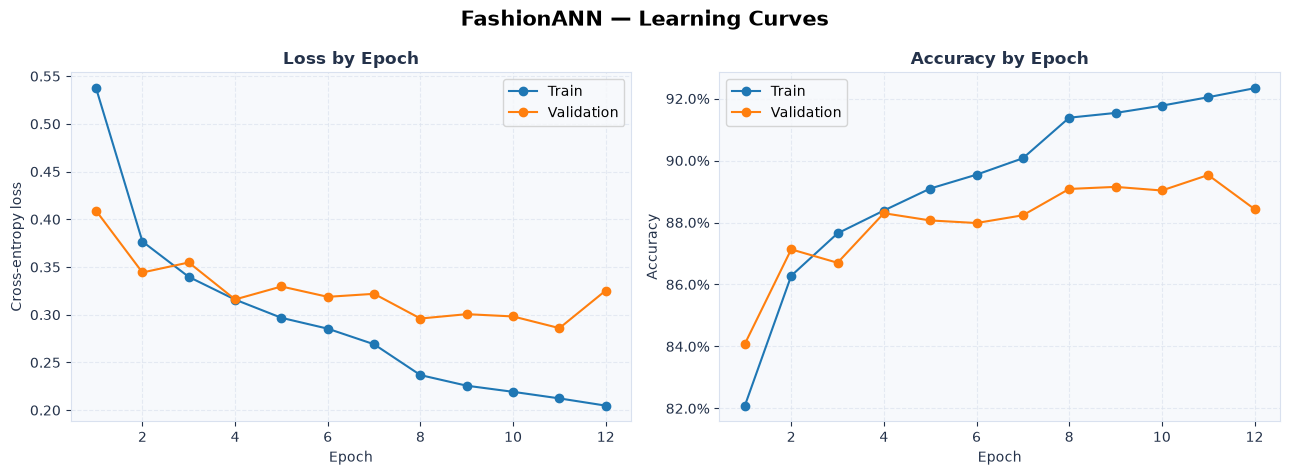

In [65]:
# Matplotlib: inspect loss and accuracy trajectories on a shared epoch axis.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train")
axes[0].plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation")
axes[0].set_title("Loss by Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(True, linestyle="--")
axes[1].plot(history_df["epoch"], history_df["train_accuracy"], marker="o", label="Train")
axes[1].plot(history_df["epoch"], history_df["val_accuracy"], marker="o", label="Validation")
axes[1].set_title("Accuracy by Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[1].legend()
axes[1].grid(True, linestyle="--")
fig.suptitle("FashionANN — Learning Curves", fontsize=15)
fig.tight_layout()
save_matplotlib(fig, "22_ann_learning_curves.png")
plt.show()
plt.close(fig)

In [66]:
# Plotly: interactive learning curves for loss and accuracy.
history_long = history_df.melt(
    id_vars="epoch",
    value_vars=["train_loss", "val_loss", "train_accuracy", "val_accuracy"],
    var_name="metric",
    value_name="value",
)
fig = px.line(
    history_long, x="epoch", y="value", color="metric", markers=True,
    title="FashionANN — Interactive Training History",
    color_discrete_sequence=["#355C7D", "#F4A261", "#2A9D8F", "#C06C84"],
)
fig.update_layout(template="plotly_white", title_x=0.02, xaxis_title="Epoch", yaxis_title="Metric value")
save_plotly(fig, "23_ann_learning_curves_interactive.html")
fig.show()

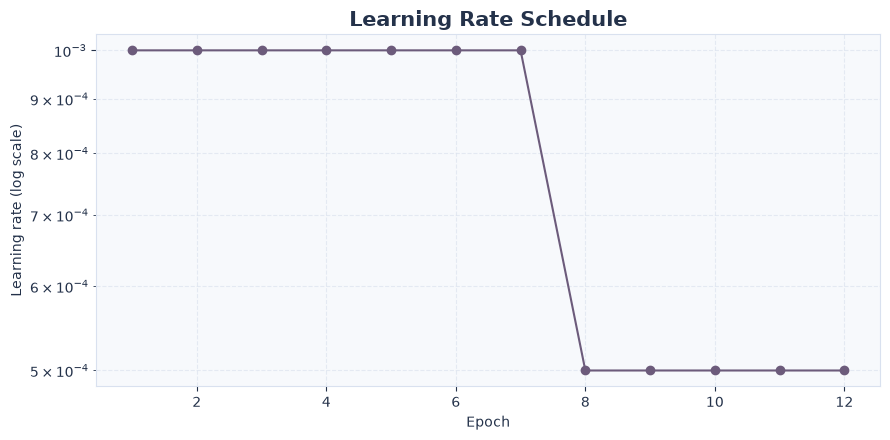

In [67]:
# Track the learning-rate schedule across completed epochs.
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(history_df["epoch"], history_df["learning_rate"], marker="o", color="#6C5B7B")
ax.set_yscale("log")
ax.set_title("Learning Rate Schedule", fontsize=15)
ax.set_xlabel("Epoch")
ax.set_ylabel("Learning rate (log scale)")
ax.grid(True, which="both", linestyle="--")
fig.tight_layout()
save_matplotlib(fig, "24_learning_rate_schedule.png")
plt.show()
plt.close(fig)

## 8. Evaluate the ANN on the held-out test set

The best validation checkpoint is evaluated once against the separate test CSV. The section reports aggregate and per-class metrics, confusion patterns, probability confidence, and calibration.

In [68]:
def collect_model_predictions(model, loader):
    """Collect labels, predictions, and softmax probabilities in dataset order."""
    model.eval()
    all_labels, all_predictions, all_probabilities = [], [], []
    with torch.no_grad():
        for features, labels in loader:
            features = features.to(DEVICE, non_blocking=True)
            logits = model(features)
            probabilities = torch.softmax(logits, dim=1)
            all_labels.append(labels.numpy())
            all_predictions.append(probabilities.argmax(dim=1).cpu().numpy())
            all_probabilities.append(probabilities.cpu().numpy())
    return np.concatenate(all_labels), np.concatenate(all_predictions), np.concatenate(all_probabilities)

In [69]:
# Run inference over the complete held-out test DataLoader.
ann_y_true, ann_y_pred, ann_test_probabilities = collect_model_predictions(model, test_loader)
print("True labels       :", ann_y_true.shape)
print("Predicted labels  :", ann_y_pred.shape)
print("Probability matrix:", ann_test_probabilities.shape)

True labels       : (10000,)
Predicted labels  : (10000,)
Probability matrix: (10000, 10)


In [70]:
# Report final test accuracy and cross-entropy loss for the selected ANN checkpoint.
ann_test_accuracy = accuracy_score(ann_y_true, ann_y_pred)
ann_test_metrics = evaluate_one_epoch(model, test_loader, criterion)
ann_test_confidence = ann_test_probabilities.max(axis=1)
ann_correct_mask = ann_y_true == ann_y_pred
print(f"ANN test accuracy : {ann_test_accuracy:.2%}")
print(f"ANN test loss     : {ann_test_metrics['loss']:.4f}")
print(f"Correct / total   : {ann_correct_mask.sum():,} / {len(ann_y_true):,}")

ANN test accuracy : 90.07%
ANN test loss     : 0.2778
Correct / total   : 9,007 / 10,000


In [71]:
# Create a detailed classification report for the ANN.
ann_report_dict = classification_report(
    ann_y_true, ann_y_pred,
    labels=np.arange(NUM_CLASSES), target_names=CLASS_NAMES,
    output_dict=True, zero_division=0,
)
ann_report_df = pd.DataFrame(ann_report_dict).T
display(ann_report_df.style.format({
    "precision": "{:.3f}", "recall": "{:.3f}",
    "f1-score": "{:.3f}", "support": "{:,.0f}",
}))

,precision,recall,f1-score,support
T-shirt/top,0.854,0.830,0.842,"1,000"
Trouser,0.982,0.986,0.984,"1,000"
Pullover,0.825,0.851,0.838,"1,000"
Dress,0.892,0.930,0.910,"1,000"
Coat,0.838,0.873,0.855,"1,000"
Sandal,0.965,0.966,0.966,"1,000"
Shirt,0.753,0.692,0.721,"1,000"
Sneaker,0.939,0.956,0.947,"1,000"
Bag,0.992,0.971,0.981,"1,000"
Ankle boot,0.962,0.952,0.957,"1,000"


In [72]:
# Calculate the ANN test confusion matrix.
ann_cm = confusion_matrix(ann_y_true, ann_y_pred, labels=np.arange(NUM_CLASSES))
print("Confusion matrix shape:", ann_cm.shape)
print("Total evaluated images:", int(ann_cm.sum()))

Confusion matrix shape: (10, 10)
Total evaluated images: 10000


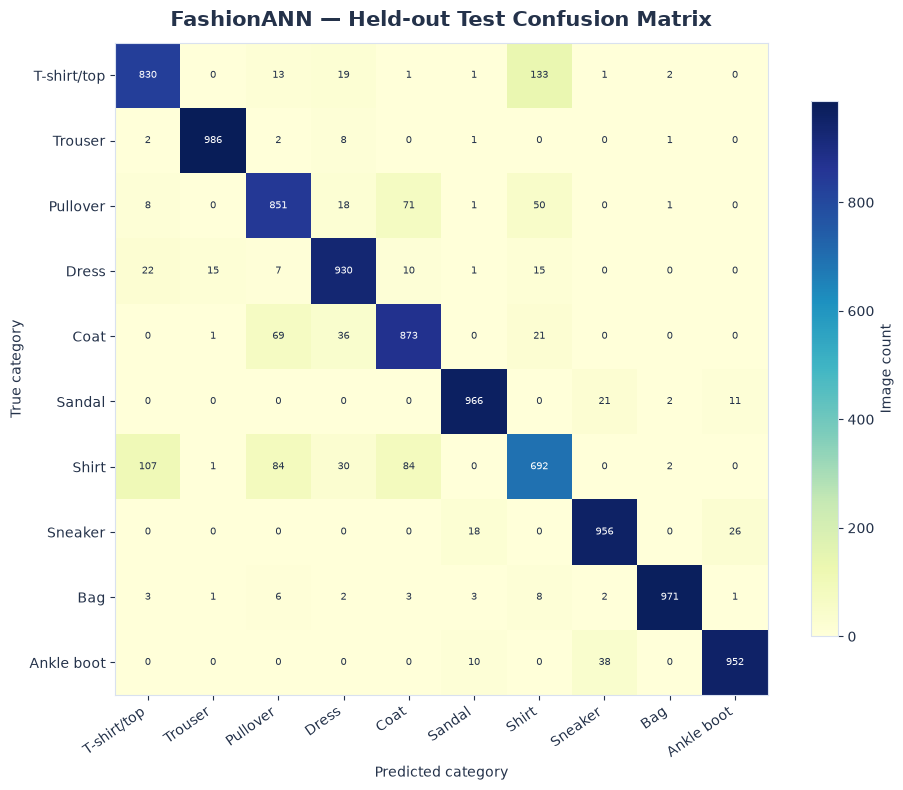

In [73]:
# Matplotlib: annotated ANN confusion matrix.
fig, ax = plt.subplots(figsize=(10, 8))
image_plot = ax.imshow(ann_cm, cmap="YlGnBu")
ax.set_title("FashionANN — Held-out Test Confusion Matrix", fontsize=15, pad=12)
ax.set_xlabel("Predicted category")
ax.set_ylabel("True category")
ax.set_xticks(np.arange(NUM_CLASSES), labels=CLASS_NAMES, rotation=35, ha="right")
ax.set_yticks(np.arange(NUM_CLASSES), labels=CLASS_NAMES)
threshold = ann_cm.max() * 0.55
for row in range(NUM_CLASSES):
    for col in range(NUM_CLASSES):
        value = ann_cm[row, col]
        ax.text(col, row, f"{value:,}", ha="center", va="center", fontsize=7,
                color="white" if value > threshold else TEXT_COLOR)
fig.colorbar(image_plot, ax=ax, shrink=0.82, label="Image count")
fig.tight_layout()
save_matplotlib(fig, "25_ann_confusion_matrix.png")
plt.show()
plt.close(fig)

In [74]:
# Plotly: interactive ANN confusion matrix with hover details.
fig = go.Figure(data=go.Heatmap(
    z=ann_cm, x=CLASS_NAMES, y=CLASS_NAMES,
    colorscale="YlGnBu",
    hovertemplate="True: %{y}<br>Predicted: %{x}<br>Images: %{z:,}<extra></extra>",
))
fig.update_layout(
    title="FashionANN — Interactive Confusion Matrix",
    xaxis_title="Predicted category", yaxis_title="True category",
    template="plotly_white", title_x=0.02,
)
save_plotly(fig, "26_ann_confusion_matrix_interactive.html")
fig.show()

In [75]:
# Calculate class-wise ANN metrics in a presentation-ready table.
ann_precision, ann_recall, ann_f1, ann_support = precision_recall_fscore_support(
    ann_y_true, ann_y_pred, labels=np.arange(NUM_CLASSES), zero_division=0
)
ann_class_metrics = pd.DataFrame({
    "class_name": CLASS_NAMES,
    "precision": ann_precision,
    "recall": ann_recall,
    "f1_score": ann_f1,
    "support": ann_support,
})
display(ann_class_metrics.style.format({
    "precision": "{:.3f}", "recall": "{:.3f}", "f1_score": "{:.3f}", "support": "{:,.0f}"
}))

,class_name,precision,recall,f1_score,support
0,T-shirt/top,0.854,0.830,0.842,"1,000"
1,Trouser,0.982,0.986,0.984,"1,000"
2,Pullover,0.825,0.851,0.838,"1,000"
3,Dress,0.892,0.930,0.910,"1,000"
4,Coat,0.838,0.873,0.855,"1,000"
5,Sandal,0.965,0.966,0.966,"1,000"
6,Shirt,0.753,0.692,0.721,"1,000"
7,Sneaker,0.939,0.956,0.947,"1,000"
8,Bag,0.992,0.971,0.981,"1,000"
9,Ankle boot,0.962,0.952,0.957,"1,000"


In [76]:
# Plotly: compare precision, recall, and F1 across fashion categories.
ann_metrics_long = ann_class_metrics.melt(
    id_vars="class_name", value_vars=["precision", "recall", "f1_score"],
    var_name="metric", value_name="score",
)
fig = px.bar(
    ann_metrics_long, x="class_name", y="score", color="metric", barmode="group",
    title="FashionANN — Per-class Precision, Recall, and F1",
    color_discrete_sequence=["#355C7D", "#2A9D8F", "#C06C84"],
)
fig.update_layout(template="plotly_white", title_x=0.02, yaxis_range=[0, 1.05])
save_plotly(fig, "27_ann_per_class_metrics.html")
fig.show()

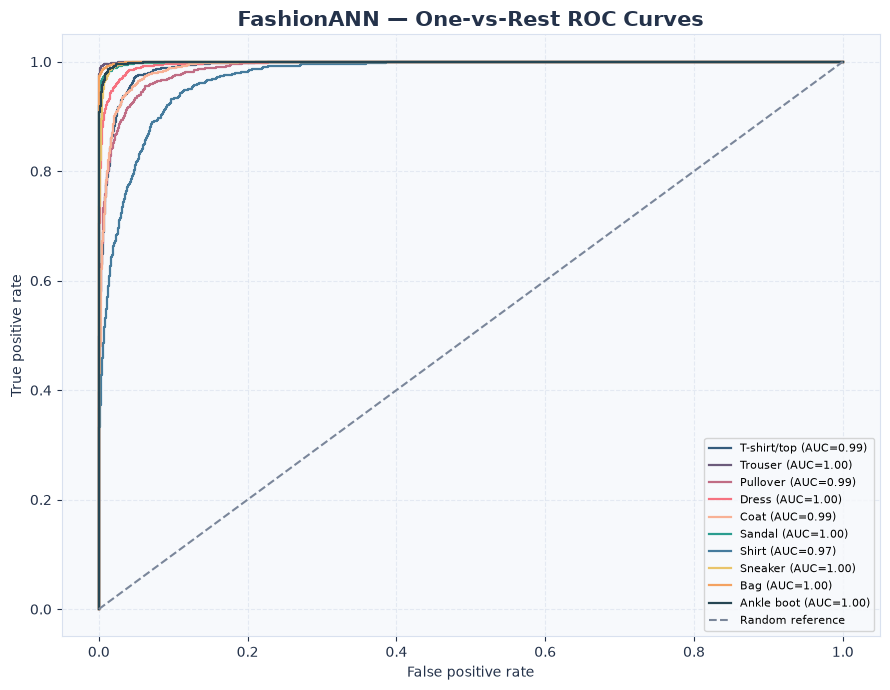

In [77]:
# Plot one-vs-rest ROC curves for all ten ANN output classes.
ann_roc_rows = []
fig, ax = plt.subplots(figsize=(9, 7))
for class_id in range(NUM_CLASSES):
    fpr, tpr, _ = roc_curve(y_test_binary[:, class_id], ann_test_probabilities[:, class_id])
    class_auc = auc(fpr, tpr)
    ann_roc_rows.append({"class_name": CLASS_NAMES[class_id], "auc": class_auc})
    ax.plot(fpr, tpr, color=PALETTE[class_id], linewidth=1.6,
            label=f"{CLASS_NAMES[class_id]} (AUC={class_auc:.2f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="#7A869A", label="Random reference")
ax.set_title("FashionANN — One-vs-Rest ROC Curves", fontsize=15)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend(loc="lower right", fontsize=8)
ax.grid(True, linestyle="--")
fig.tight_layout()
save_matplotlib(fig, "28_ann_roc_curves.png")
plt.show()
plt.close(fig)
ann_roc_df = pd.DataFrame(ann_roc_rows)

In [78]:
# Measure confidence calibration using the maximum class probability per image.
ann_observed_accuracy, ann_mean_confidence = calibration_curve(
    ann_correct_mask.astype(int), ann_test_confidence, n_bins=10, strategy="uniform"
)
calibration_df = pd.DataFrame({
    "mean_confidence": ann_mean_confidence,
    "observed_accuracy": ann_observed_accuracy,
})
display(calibration_df.style.format("{:.3f}"))

,mean_confidence,observed_accuracy
0,0.277,0.571
1,0.350,0.378
2,0.458,0.371
3,0.549,0.524
4,0.653,0.610
5,0.752,0.713
6,0.855,0.777
7,0.988,0.980


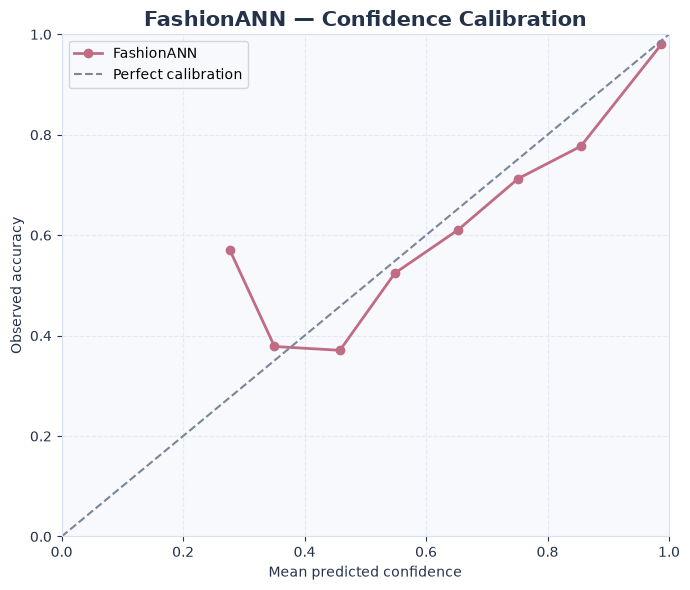

In [79]:
# Matplotlib: reliability diagram comparing confidence with observed accuracy.
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(ann_mean_confidence, ann_observed_accuracy, marker="o", linewidth=2,
        color="#C06C84", label="FashionANN")
ax.plot([0, 1], [0, 1], linestyle="--", color="#7A869A", label="Perfect calibration")
ax.set_title("FashionANN — Confidence Calibration", fontsize=15)
ax.set_xlabel("Mean predicted confidence")
ax.set_ylabel("Observed accuracy")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend()
ax.grid(True, linestyle="--")
fig.tight_layout()
save_matplotlib(fig, "29_ann_calibration_curve.png")
plt.show()
plt.close(fig)

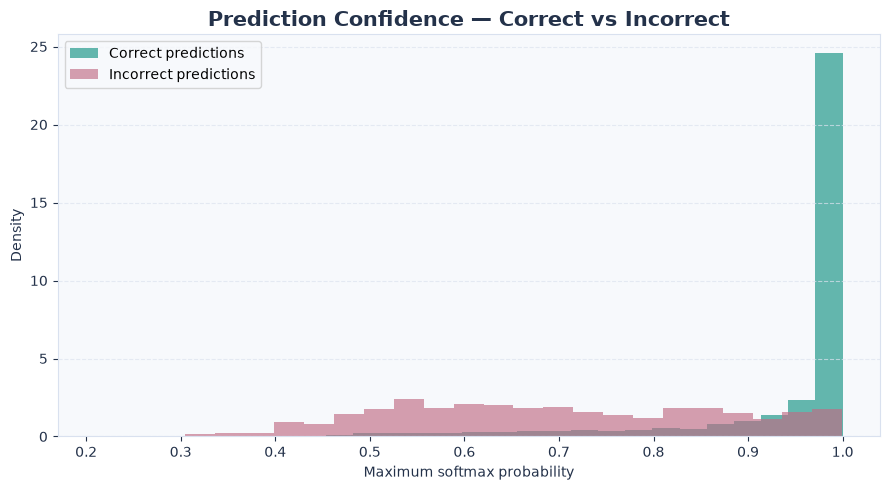

In [80]:
# Compare confidence distributions for correct and incorrect ANN predictions.
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(ann_test_confidence[ann_correct_mask], bins=25, alpha=0.72, density=True,
        color="#2A9D8F", label="Correct predictions")
ax.hist(ann_test_confidence[~ann_correct_mask], bins=25, alpha=0.65, density=True,
        color="#C06C84", label="Incorrect predictions")
ax.set_title("Prediction Confidence — Correct vs Incorrect", fontsize=15)
ax.set_xlabel("Maximum softmax probability")
ax.set_ylabel("Density")
ax.legend()
ax.grid(axis="y", linestyle="--")
fig.tight_layout()
save_matplotlib(fig, "30_ann_confidence_distribution.png")
plt.show()
plt.close(fig)

In [81]:
# Build a row-level table of ANN errors, including confidence and probability margin.
ann_error_indices = np.flatnonzero(~ann_correct_mask)
ann_sorted_probabilities = np.sort(ann_test_probabilities, axis=1)
ann_probability_margin = ann_sorted_probabilities[:, -1] - ann_sorted_probabilities[:, -2]
ann_error_df = pd.DataFrame({
    "test_index": ann_error_indices,
    "true_label": ann_y_true[ann_error_indices],
    "predicted_label": ann_y_pred[ann_error_indices],
    "true_class": [CLASS_NAMES[int(value)] for value in ann_y_true[ann_error_indices]],
    "predicted_class": [CLASS_NAMES[int(value)] for value in ann_y_pred[ann_error_indices]],
    "confidence": ann_test_confidence[ann_error_indices],
    "probability_margin": ann_probability_margin[ann_error_indices],
}).sort_values("confidence", ascending=False)
print(f"Misclassified test images: {len(ann_error_df):,}")
display(ann_error_df.head(15).style.format({"confidence": "{:.1%}", "probability_margin": "{:.1%}"}))

Misclassified test images: 993


,test_index,true_label,predicted_label,true_class,predicted_class,confidence,probability_margin
480,4640,8,7,Bag,Sneaker,100.0%,99.9%
220,2128,0,3,T-shirt/top,Dress,99.9%,99.9%
751,7402,5,7,Sandal,Sneaker,99.9%,99.8%
361,3399,7,9,Sneaker,Ankle boot,99.9%,99.8%
605,5923,5,7,Sandal,Sneaker,99.9%,99.8%
344,3261,9,5,Ankle boot,Sandal,99.8%,99.7%
31,305,6,2,Shirt,Pullover,99.8%,99.7%
543,5232,3,0,Dress,T-shirt/top,99.8%,99.5%
594,5779,9,7,Ankle boot,Sneaker,99.7%,99.5%
247,2313,6,0,Shirt,T-shirt/top,99.7%,99.4%


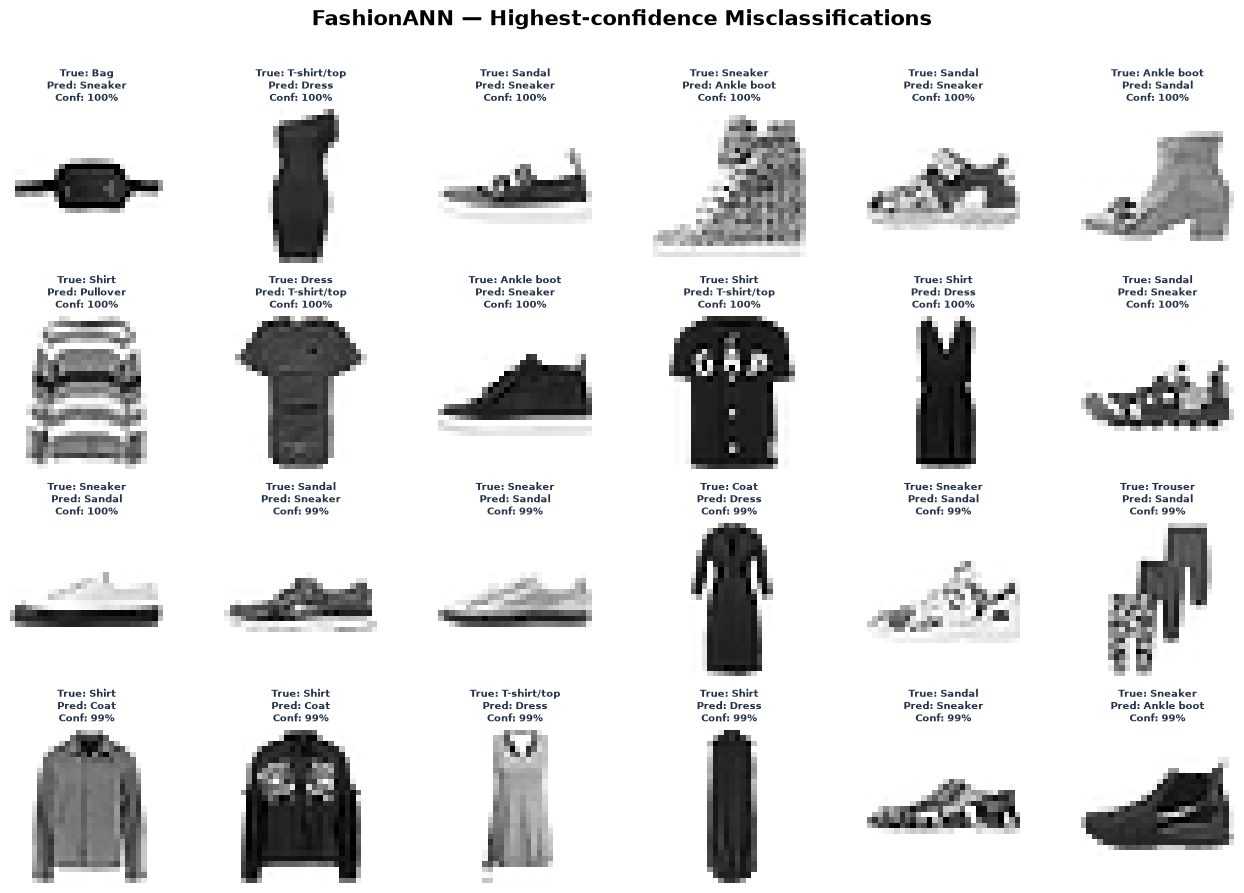

In [82]:
# Display a grid of incorrectly classified test images with true and predicted labels.
review_errors = ann_error_df.head(24)
if len(review_errors) == 0:
    print("No misclassified test images were found.")
else:
    rows = int(np.ceil(len(review_errors) / 6))
    fig, axes = plt.subplots(rows, 6, figsize=(13, rows * 2.2))
    axes = np.array(axes).reshape(-1)
    for ax, (_, record) in zip(axes, review_errors.iterrows()):
        image = X_test[int(record["test_index"])].reshape(28, 28)
        ax.imshow(image, cmap="gray_r", vmin=0, vmax=1)
        ax.set_title(f"True: {record['true_class']}\nPred: {record['predicted_class']}\nConf: {record['confidence']:.0%}", fontsize=7)
        ax.axis("off")
    for ax in axes[len(review_errors):]:
        ax.axis("off")
    fig.suptitle("FashionANN — Highest-confidence Misclassifications", fontsize=15, y=1.01)
    fig.tight_layout()
    save_matplotlib(fig, "31_ann_misclassified_gallery.png")
    plt.show()
plt.close(fig)

In [83]:
# Rank the ANN's most common true-class to predicted-class confusions.
ann_confusion_pairs = []
for true_id in range(NUM_CLASSES):
    for predicted_id in range(NUM_CLASSES):
        if true_id != predicted_id and ann_cm[true_id, predicted_id] > 0:
            ann_confusion_pairs.append({
                "true_class": CLASS_NAMES[true_id],
                "predicted_class": CLASS_NAMES[predicted_id],
                "confusion": f"{CLASS_NAMES[true_id]} → {CLASS_NAMES[predicted_id]}",
                "count": int(ann_cm[true_id, predicted_id]),
            })
ann_confusion_pairs_df = pd.DataFrame(ann_confusion_pairs).sort_values("count", ascending=False).head(15)
display(ann_confusion_pairs_df)

,true_class,predicted_class,confusion,count
4,T-shirt/top,Shirt,T-shirt/top → Shirt,133
31,Shirt,T-shirt/top,Shirt → T-shirt/top,107
33,Shirt,Pullover,Shirt → Pullover,84
35,Shirt,Coat,Shirt → Coat,84
14,Pullover,Coat,Pullover → Coat,71
25,Coat,Pullover,Coat → Pullover,69
16,Pullover,Shirt,Pullover → Shirt,50
49,Ankle boot,Sneaker,Ankle boot → Sneaker,38
26,Coat,Dress,Coat → Dress,36
34,Shirt,Dress,Shirt → Dress,30


In [84]:
# Plotly: explore the most frequent ANN confusion pairs interactively.
fig = px.bar(
    ann_confusion_pairs_df.sort_values("count"),
    x="count", y="confusion", orientation="h", color="count",
    color_continuous_scale="Tealgrn", title="FashionANN — Most Frequent Misclassification Pairs",
    labels={"count": "Number of images", "confusion": "True → predicted category"},
)
fig.update_layout(template="plotly_white", title_x=0.02, coloraxis_showscale=False)
save_plotly(fig, "32_ann_top_confusion_pairs.html")
fig.show()

## 9. Single-image inference and model comparison

The final section demonstrates how to classify one 28×28 image, inspect the top predicted categories, and compare the ANN against the scikit-learn and dummy baselines.

In [85]:
def predict_fashion_image(image, model=model, top_k=5):
    """Predict one flattened or 28×28 image; accept raw 0–255 or normalized 0–1 pixels."""
    image_array = np.asarray(image, dtype=np.float32)
    if image_array.size != 784:
        raise ValueError(f"Expected 784 pixel values, received {image_array.size}.")
    image_array = image_array.reshape(1, 784)
    if image_array.max() > 1.0:
        image_array = image_array / 255.0
    tensor = torch.tensor(image_array, dtype=torch.float32, device=DEVICE)
    model.eval()
    with torch.no_grad():
        probabilities = torch.softmax(model(tensor), dim=1).cpu().numpy()[0]
    top_indices = np.argsort(probabilities)[::-1][:top_k]
    top_table = pd.DataFrame({
        "class_id": top_indices,
        "class_name": [CLASS_NAMES[int(index)] for index in top_indices],
        "probability": probabilities[top_indices],
    })
    return top_table, probabilities

In [86]:
# Select one held-out test example and run single-image inference.
example_index = min(17, len(X_test) - 1)
example_image = X_test[example_index]
example_true_label = int(y_test[example_index])
example_topk, example_probabilities = predict_fashion_image(example_image, top_k=5)
example_predicted_label = int(np.argmax(example_probabilities))
print("True category     :", CLASS_NAMES[example_true_label])
print("Predicted category:", CLASS_NAMES[example_predicted_label])
display(example_topk.style.format({"probability": "{:.2%}"}))

True category     : Dress
Predicted category: Dress


,class_id,class_name,probability
0,3,Dress,99.82%
1,0,T-shirt/top,0.08%
2,6,Shirt,0.06%
3,2,Pullover,0.02%
4,1,Trouser,0.01%


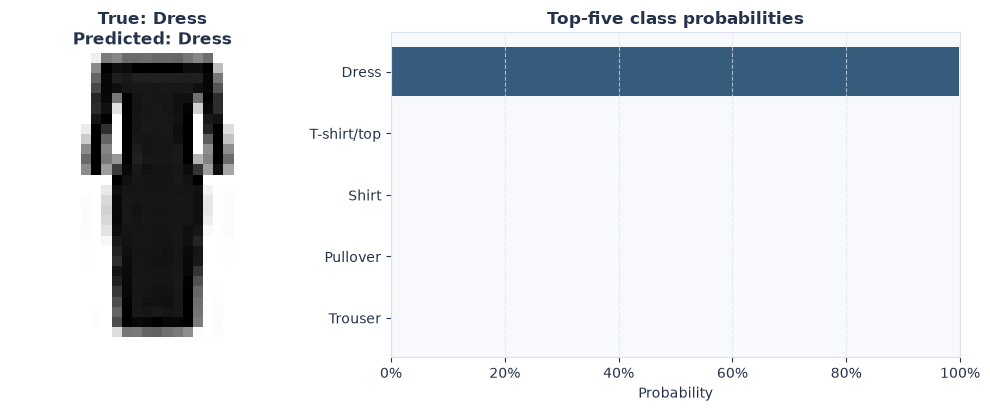

In [87]:
# Visualise the selected image and its top-five prediction probabilities.
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), gridspec_kw={"width_ratios": [1, 2]})
axes[0].imshow(example_image.reshape(28, 28), cmap="gray_r", vmin=0, vmax=1)
axes[0].set_title(f"True: {CLASS_NAMES[example_true_label]}\nPredicted: {CLASS_NAMES[example_predicted_label]}")
axes[0].axis("off")
axes[1].barh(example_topk["class_name"].iloc[::-1], example_topk["probability"].iloc[::-1], color=PALETTE[:5][::-1])
axes[1].set_xlim(0, 1)
axes[1].xaxis.set_major_formatter(PercentFormatter(1.0))
axes[1].set_title("Top-five class probabilities")
axes[1].set_xlabel("Probability")
axes[1].grid(axis="x", linestyle="--")
fig.tight_layout()
save_matplotlib(fig, "33_single_image_prediction.png")
plt.show()
plt.close(fig)

In [88]:
# Compare test accuracy across the dummy, scikit-learn, and PyTorch models.
model_comparison = pd.DataFrame([
    {"model": "DummyClassifier", "test_accuracy": dummy_test_accuracy, "training_seconds": np.nan},
    {"model": "SGDClassifier", "test_accuracy": sgd_test_accuracy, "training_seconds": sgd_training_seconds},
    {"model": "FashionANN (PyTorch)", "test_accuracy": ann_test_accuracy, "training_seconds": training_duration_seconds},
])
model_comparison["error_rate"] = 1 - model_comparison["test_accuracy"]
display(model_comparison.style.format({
    "test_accuracy": "{:.2%}", "error_rate": "{:.2%}", "training_seconds": "{:.1f}"
}))

,model,test_accuracy,training_seconds,error_rate
0,DummyClassifier,10.00%,nan,90.00%
1,SGDClassifier,82.55%,2.7,17.45%
2,FashionANN (PyTorch),90.07%,59.5,9.93%


In [89]:
# Plotly: compare model accuracy with the same held-out test set.
fig = px.bar(
    model_comparison, x="model", y="test_accuracy", color="model",
    color_discrete_sequence=["#A8B0BC", "#457B9D", "#2A9D8F"],
    title="Model Comparison — Held-out Test Accuracy",
    labels={"model": "Model", "test_accuracy": "Test accuracy"},
    text=model_comparison["test_accuracy"].map(lambda value: f"{value:.1%}"),
)
fig.update_traces(textposition="outside")
fig.update_layout(template="plotly_white", title_x=0.02, showlegend=False, yaxis_range=[0, 1.05])
save_plotly(fig, "34_model_accuracy_comparison.html")
fig.show()

## 10. Export all outputs

The export cells write machine-readable files and model checkpoints to `artifacts/`. Figures remain in `images/`. No output CSV, JSON, or model checkpoint is written to the project root.

In [90]:
# Export the overall model comparison and individual baseline diagnostics.
save_csv(model_comparison, "model_comparison.csv")
save_csv(sgd_class_metrics, "sgd_per_class_metrics.csv")
save_csv(sgd_roc_df, "sgd_roc_auc_by_class.csv")
save_csv(sgd_pr_df, "sgd_average_precision_by_class.csv")
print("Scikit-learn and model comparison tables exported.")

Scikit-learn and model comparison tables exported.


In [91]:
# Export label mapping, class distribution, data-quality checks, and dataset profile.
save_csv(label_map, "label_mapping.csv")
save_csv(class_distribution, "class_distribution.csv")
save_csv(data_quality, "data_quality_report.csv")
save_csv(dataset_overview, "dataset_overview.csv")
save_csv(split_distribution, "split_class_distribution.csv")
print("Dataset audit tables exported.")

Dataset audit tables exported.


In [92]:
# Export predictions for every held-out test image from all model stages.
predictions_df = pd.DataFrame({
    "test_index": np.arange(len(y_test)),
    "true_label": y_test,
    "true_class": [CLASS_NAMES[int(value)] for value in y_test],
    "dummy_prediction": dummy_test_predictions,
    "sgd_prediction": sgd_test_predictions,
    "ann_prediction": ann_y_pred,
    "ann_confidence": ann_test_confidence,
    "ann_correct": ann_correct_mask,
})
predictions_df.to_csv(ARTIFACTS_DIR / "test_set_predictions.csv", index=False)
print("Saved predictions:", ARTIFACTS_DIR / "test_set_predictions.csv")

Saved predictions: C:\Users\as178\OneDrive\Documents\ROADMAP\Semester 3\Deep Learning\Pytorch\artifacts\test_set_predictions.csv


In [93]:
# Export detailed scikit-learn and ANN classification reports.
save_csv(sgd_report_df.reset_index(names="class_or_average"), "sgd_classification_report.csv")
save_csv(ann_report_df.reset_index(names="class_or_average"), "ann_classification_report.csv")
print("Classification reports exported.")

Classification reports exported.


In [94]:
# Export raw confusion matrices and the top confusion-pair summaries.
sgd_cm_df = pd.DataFrame(sgd_cm, index=CLASS_NAMES, columns=CLASS_NAMES)
ann_cm_df = pd.DataFrame(ann_cm, index=CLASS_NAMES, columns=CLASS_NAMES)
sgd_cm_df.to_csv(ARTIFACTS_DIR / "sgd_confusion_matrix.csv", index_label="true_class")
ann_cm_df.to_csv(ARTIFACTS_DIR / "ann_confusion_matrix.csv", index_label="true_class")
save_csv(ann_confusion_pairs_df, "ann_top_confusion_pairs.csv")
save_csv(sgd_confusion_pairs_df, "sgd_top_confusion_pairs.csv")
print("Confusion matrix exports completed.")

Confusion matrix exports completed.


In [95]:
# Export ANN per-class metrics, calibration bins, and ROC summaries.
save_csv(ann_class_metrics, "ann_per_class_metrics.csv")
save_csv(calibration_df, "ann_calibration_bins.csv")
save_csv(ann_roc_df, "ann_roc_auc_by_class.csv")
print("ANN diagnostic tables exported.")

ANN diagnostic tables exported.


In [96]:
# Export PCA and training-history tables for further analysis outside this notebook.
save_csv(explained_variance_df, "pca_explained_variance.csv")
save_csv(top_pixels_df, "highest_variance_pixels.csv")
save_csv(history_df, "ann_training_history.csv")
save_csv(brightness_df, "class_mean_brightness.csv")
print("PCA, training, and EDA tables exported.")

PCA, training, and EDA tables exported.


In [97]:
# Assemble evaluation metrics and a reproducible run configuration.
evaluation_metrics = {
    "dummy_test_accuracy": float(dummy_test_accuracy),
    "sgd_test_accuracy": float(sgd_test_accuracy),
    "ann_test_accuracy": float(ann_test_accuracy),
    "ann_test_loss": float(ann_test_metrics["loss"]),
    "ann_best_validation_loss": float(best_val_loss),
    "ann_best_validation_accuracy": float(best_val_accuracy),
    "ann_best_epoch": int(best_epoch),
    "ann_epochs_completed": int(len(history_df)),
    "ann_training_duration_seconds": float(training_duration_seconds),
    "ann_misclassified_count": int(len(ann_error_indices)),
    "ann_test_sample_count": int(len(y_test)),
    "trainable_parameters": int(trainable_parameters),
}
run_config = {
    "seed": SEED,
    "device": str(DEVICE),
    "train_csv": str(TRAIN_CSV_PATH),
    "test_csv": str(TEST_CSV_PATH),
    "train_rows": int(len(train_df)),
    "test_rows": int(len(test_df)),
    "validation_size": VALIDATION_SIZE,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "dropout_rate": DROPOUT_RATE,
    "class_names": CLASS_NAMES,
}
save_json(evaluation_metrics, "evaluation_metrics.json")
save_json(run_config, "run_configuration.json")
print("Evaluation metrics and run configuration saved.")

Evaluation metrics and run configuration saved.


In [98]:
# Save the trained scikit-learn and PyTorch model files in the artifacts directory.
sgd_model_path = ARTIFACTS_DIR / "fashion_mnist_sgd_classifier.joblib"
ann_model_path = ARTIFACTS_DIR / "fashion_mnist_ann_state_dict.pth"
dump(sgd_model, sgd_model_path)
torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": CLASS_NAMES,
    "input_features": 784,
    "num_classes": NUM_CLASSES,
    "hidden_layers": [512, 256, 128],
    "dropout_rate": DROPOUT_RATE,
    "best_epoch": best_epoch,
    "best_validation_loss": float(best_val_loss),
    "test_accuracy": float(ann_test_accuracy),
    "seed": SEED,
}, ann_model_path)
print("Saved scikit-learn model:", sgd_model_path)
print("Saved PyTorch checkpoint :", ann_model_path)

Saved scikit-learn model: C:\Users\as178\OneDrive\Documents\ROADMAP\Semester 3\Deep Learning\Pytorch\artifacts\fashion_mnist_sgd_classifier.joblib
Saved PyTorch checkpoint : C:\Users\as178\OneDrive\Documents\ROADMAP\Semester 3\Deep Learning\Pytorch\artifacts\fashion_mnist_ann_state_dict.pth


In [99]:
# Plotly: compare one-vs-rest ROC-AUC values across ANN output classes.
fig = px.bar(
    ann_roc_df.sort_values("auc", ascending=True),
    x="auc", y="class_name", orientation="h", color="auc",
    color_continuous_scale="Viridis", title="FashionANN — ROC-AUC by Category",
    labels={"auc": "ROC-AUC", "class_name": "Fashion category"},
)
fig.update_layout(template="plotly_white", title_x=0.02, xaxis_range=[0, 1], coloraxis_showscale=False)
save_plotly(fig, "35_ann_roc_auc_by_class.html")
fig.show()

In [100]:
# Save an export manifest and print a concise final scorecard.
all_output_files = sorted(
    [path for path in IMAGES_DIR.rglob("*") if path.is_file()] +
    [path for path in ARTIFACTS_DIR.rglob("*") if path.is_file()]
)
manifest = {
    "project": "Fashion-MNIST Classification",
    "images_directory": str(IMAGES_DIR.resolve()),
    "artifacts_directory": str(ARTIFACTS_DIR.resolve()),
    "file_count": len(all_output_files),
    "files": [
        {"path": str(path.relative_to(PROJECT_ROOT)), "size_bytes": path.stat().st_size}
        for path in all_output_files
    ],
}
save_json(manifest, "output_manifest.json")

print("=" * 68)
print("FASHION-MNIST — FINAL EXPERIMENT SCORECARD")
print("=" * 68)
print(f"DummyClassifier accuracy : {dummy_test_accuracy:.2%}")
print(f"SGDClassifier accuracy   : {sgd_test_accuracy:.2%}")
print(f"FashionANN accuracy      : {ann_test_accuracy:.2%}")
print(f"FashionANN test loss     : {ann_test_metrics['loss']:.4f}")
print(f"Best ANN epoch           : {best_epoch}")
print(f"ANN trainable parameters : {trainable_parameters:,}")
print(f"Misclassified test items : {len(ann_error_indices):,} / {len(y_test):,}")
print(f"Images folder            : {IMAGES_DIR.resolve()}")
print(f"Artifacts folder         : {ARTIFACTS_DIR.resolve()}")
print(f"Exported files           : {len(all_output_files) + 1:,} (including this manifest)")
print("=" * 68)

FASHION-MNIST — FINAL EXPERIMENT SCORECARD
DummyClassifier accuracy : 10.00%
SGDClassifier accuracy   : 82.55%
FashionANN accuracy      : 90.07%
FashionANN test loss     : 0.2778
Best ANN epoch           : 11
ANN trainable parameters : 569,226
Misclassified test items : 993 / 10,000
Images folder            : C:\Users\as178\OneDrive\Documents\ROADMAP\Semester 3\Deep Learning\Pytorch\images
Artifacts folder         : C:\Users\as178\OneDrive\Documents\ROADMAP\Semester 3\Deep Learning\Pytorch\artifacts
Exported files           : 133 (including this manifest)


## 11. How to read the results

- **Accuracy** is the overall share of correctly classified test images. It should not be interpreted alone; review macro/weighted F1 and the confusion matrix as well.
- **Precision** indicates how often predictions for a category are correct. **Recall** indicates how many actual examples of that category were found. **F1-score** balances precision and recall.
- **ROC-AUC** measures class separability in a one-vs-rest framing. The calibration plot compares predicted confidence with observed correctness.
- **PCA** is an exploratory projection. The ANN and SGD classifier use all 784 normalized pixel features.
- **Error analysis** helps locate visually similar categories and suggests where additional architecture work or augmentation may help.

## 12. Output directory reference

```text
project/
├── fashion_mnist.ipynb
├── fashion-mnist_train.csv
├── fashion-mnist_test.csv
├── images/
│   ├── *.png       # Matplotlib figures
│   └── *.html      # Interactive Plotly charts
└── artifacts/
    ├── *.csv       # metrics, reports, predictions, audit tables
    ├── *.json      # metrics, config, export manifest
    ├── *.joblib    # fitted scikit-learn model
    └── *.pth       # PyTorch ANN checkpoint
```

**Suggested extensions:** compare CNN architectures, add image augmentation, tune SGD regularisation, use learning-rate sweeps, or evaluate per-class error costs. Keep the test CSV untouched while selecting experiments.